# Sesión 02 — Ejercicios propuestos

**Curso:** Ingeniería del Conocimiento (ISO56B)

**Estudiante:** Echegoyen Rojas Anahi Shannel

**Periodo:** 2026-II | Universidad Nacional del Centro del Perú

## Enunciados

### Ejercicio 1 — Optimización con GridSearchCV
Para cada modelo, realice una búsqueda exhaustiva de hiperparámetros con `GridSearchCV(cv=5, scoring='f1')`. Parámetros sugeridos:
- **LogisticRegression:** C=[0.01, 0.1, 1, 10, 100]
- **DecisionTree:** max_depth=[3,5,7,10,None], min_samples_leaf=[1,5,10]
- **SVM:** C=[0.1,1,10], gamma=[0.001,0.01,0.1]
- **KNN:** n_neighbors=[3,5,9,15,21], weights=['uniform','distance']

Compare los mejores modelos optimizados.

### Ejercicio 2 — Manejo de desbalance con class_weight y SMOTE
Entrene los 4 modelos con `class_weight='balanced'`. Compare Recall de la clase maligna con y sin balanceo. Además, aplique SMOTE:
```python
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_train, y_train)
```

### Ejercicio 3 — Dataset propio
Seleccione un dataset de clasificación de Kaggle/UCI (mín. 500 registros, 5 features). Aplique los 4 modelos + al menos 1 adicional (Random Forest, Gradient Boosting o Naive Bayes). Documente métricas, curvas ROC, matriz de selección y justificación del mejor modelo.

---
## 0. Configuración del entorno

In [1]:
# 0.1  Instalar imbalanced-learn si no está disponible (necesario para SMOTE en el Ejercicio 2)
import importlib.util, subprocess, sys
if importlib.util.find_spec('imblearn') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'imbalanced-learn'])
print('✓ imbalanced-learn disponible')

✓ imbalanced-learn disponible


In [2]:
# 0.2  Librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             precision_score, recall_score, f1_score, roc_curve, auc)

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')
print('✓ Librerías cargadas correctamente')

✓ Librerías cargadas correctamente


---
## 1. Datos y modelos base (Breast Cancer Wisconsin)

Los Ejercicios 1 y 2 trabajan sobre el dataset de la sesión. Aquí se reproduce lo mínimo necesario de las secciones 2, 4 y 9 del notebook de la sesión: carga, partición train/test, `StratifiedKFold` y los 4 modelos base con su tabla de métricas (`metrics_df`), que el Ejercicio 1 usa para comparar.

In [3]:
# 1.1  Carga del dataset y partición
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target          # 0 = maligno, 1 = benigno

X = df[data.feature_names].copy()
y = df['target'].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
colors_models = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12']

print(f'Dataset: {df.shape[0]} muestras, {len(data.feature_names)} features')
print(f'Entrenamiento: {X_train.shape[0]} | Test: {X_test.shape[0]}')
print(f'Proporción benigno: {y.mean():.1%}')

Dataset: 569 muestras, 30 features
Entrenamiento: 455 | Test: 114
Proporción benigno: 62.7%


In [4]:
# 1.2  Modelos base (mismos hiperparámetros que en la sesión) y tabla de métricas en test
pipe_lr = Pipeline([('scaler', StandardScaler()),
                    ('clf', LogisticRegression(max_iter=1000, random_state=42))])
pipe_dt = Pipeline([('clf', DecisionTreeClassifier(max_depth=5, min_samples_split=10,
                                                   min_samples_leaf=5, random_state=42))])
pipe_svm = Pipeline([('scaler', StandardScaler()),
                     ('clf', SVC(kernel='rbf', C=1.0, probability=True, random_state=42))])
pipe_knn = Pipeline([('scaler', StandardScaler()),
                     ('clf', KNeighborsClassifier(n_neighbors=5))])

all_models = {'Regresión Logística': pipe_lr, 'Árbol de Decisión': pipe_dt,
              'SVM (RBF)': pipe_svm, 'KNN (K=5)': pipe_knn}
all_metrics = {}
for name, model in all_models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    all_metrics[name] = {'Accuracy': accuracy_score(y_test, y_pred),
                         'Precision': precision_score(y_test, y_pred),
                         'Recall': recall_score(y_test, y_pred),
                         'F1-Score': f1_score(y_test, y_pred),
                         'AUC': auc(fpr, tpr)}
metrics_df = pd.DataFrame(all_metrics).T.round(4)
print('=== Modelos base (Test Set) ===')
metrics_df

=== Modelos base (Test Set) ===


,Accuracy,Precision,Recall,F1-Score,AUC
Regresión Logística,0.9825,0.9861,0.9861,0.9861,0.9954
Árbol de Decisión,0.9211,0.9437,0.9306,0.9371,0.9368
SVM (RBF),0.9825,0.9861,0.9861,0.9861,0.9950
KNN (K=5),0.9561,0.9589,0.9722,0.9655,0.9788


---
## Ejercicio 1 — Optimización con GridSearchCV

Se define una grilla por modelo (las sugeridas en el enunciado) y se busca la mejor combinación con validación cruzada estratificada de 5 folds y `scoring='f1'`. Se usa `cv=skf` (el mismo `StratifiedKFold(5, shuffle=True, random_state=42)` de la sección 4) para que sea equivalente a `cv=5` pero reproducible.

In [5]:
# E1.1  Búsqueda exhaustiva de hiperparámetros con GridSearchCV
from sklearn.model_selection import GridSearchCV

grids = {
    'Regresión Logística': (
        Pipeline([('scaler', StandardScaler()),
                  ('clf', LogisticRegression(max_iter=1000, random_state=42))]),
        {'clf__C': [0.01, 0.1, 1, 10, 100]}
    ),
    'Árbol de Decisión': (
        Pipeline([('clf', DecisionTreeClassifier(random_state=42))]),
        {'clf__max_depth': [3, 5, 7, 10, None],
         'clf__min_samples_leaf': [1, 5, 10]}
    ),
    'SVM (RBF)': (
        Pipeline([('scaler', StandardScaler()),
                  ('clf', SVC(kernel='rbf', probability=True, random_state=42))]),
        {'clf__C': [0.1, 1, 10],
         'clf__gamma': [0.001, 0.01, 0.1]}
    ),
    'KNN': (
        Pipeline([('scaler', StandardScaler()),
                  ('clf', KNeighborsClassifier())]),
        {'clf__n_neighbors': [3, 5, 9, 15, 21],
         'clf__weights': ['uniform', 'distance']}
    )
}

grid_results = {}
for name, (pipe, param_grid) in grids.items():
    gs = GridSearchCV(pipe, param_grid, cv=skf, scoring='f1', n_jobs=-1)
    gs.fit(X_train, y_train)
    grid_results[name] = gs
    print(f'=== {name} ===')
    print(f'  Combinaciones evaluadas: {len(gs.cv_results_["params"])}')
    print(f'  Mejores hiperparámetros: {gs.best_params_}')
    print(f'  Mejor F1 (CV 5-fold):    {gs.best_score_:.4f}\n')

=== Regresión Logística ===
  Combinaciones evaluadas: 5
  Mejores hiperparámetros: {'clf__C': 0.1}
  Mejor F1 (CV 5-fold):    0.9861

=== Árbol de Decisión ===
  Combinaciones evaluadas: 15
  Mejores hiperparámetros: {'clf__max_depth': 3, 'clf__min_samples_leaf': 5}
  Mejor F1 (CV 5-fold):    0.9460

=== SVM (RBF) ===
  Combinaciones evaluadas: 9
  Mejores hiperparámetros: {'clf__C': 10, 'clf__gamma': 0.01}
  Mejor F1 (CV 5-fold):    0.9810

=== KNN ===
  Combinaciones evaluadas: 10
  Mejores hiperparámetros: {'clf__n_neighbors': 9, 'clf__weights': 'uniform'}
  Mejor F1 (CV 5-fold):    0.9724



In [6]:
# E1.2  Evaluación en test: modelo base vs. modelo optimizado
base_names = {'Regresión Logística': 'Regresión Logística',
              'Árbol de Decisión': 'Árbol de Decisión',
              'SVM (RBF)': 'SVM (RBF)',
              'KNN': 'KNN (K=5)'}

rows = []
for name, gs in grid_results.items():
    model = gs.best_estimator_
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    rows.append({
        'Modelo': name,
        'CV F1': gs.best_score_,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'AUC': auc(fpr, tpr),
        'Recall maligno': recall_score(y_test, y_pred, pos_label=0)
    })

opt_df = pd.DataFrame(rows).set_index('Modelo').round(4)
print('=== Modelos optimizados (Test Set) ===')
display(opt_df)

comp = pd.DataFrame({
    'F1 base': [metrics_df.loc[base_names[m], 'F1-Score'] for m in opt_df.index],
    'F1 optimizado': opt_df['F1-Score'].values,
    'AUC base': [metrics_df.loc[base_names[m], 'AUC'] for m in opt_df.index],
    'AUC optimizado': opt_df['AUC'].values
}, index=opt_df.index)
comp['Δ F1'] = (comp['F1 optimizado'] - comp['F1 base']).round(4)
print('\n=== Base vs. optimizado ===')
display(comp.round(4))

=== Modelos optimizados (Test Set) ===


,CV F1,Accuracy,Precision,Recall,F1-Score,AUC,Recall maligno
Modelo,,,,,,,
Regresión Logística,0.9861,0.9737,0.9726,0.9861,0.9793,0.9957,0.9524
Árbol de Decisión,0.9460,0.9386,0.9452,0.9583,0.9517,0.9439,0.9048
SVM (RBF),0.9810,0.9825,0.9861,0.9861,0.9861,0.9977,0.9762
KNN,0.9724,0.9737,0.9600,1.0000,0.9796,0.9944,0.9286



=== Base vs. optimizado ===


,F1 base,F1 optimizado,AUC base,AUC optimizado,Δ F1
Modelo,,,,,
Regresión Logística,0.9861,0.9793,0.9954,0.9957,-0.0068
Árbol de Decisión,0.9371,0.9517,0.9368,0.9439,0.0146
SVM (RBF),0.9861,0.9861,0.9950,0.9977,0.0000
KNN,0.9655,0.9796,0.9788,0.9944,0.0141


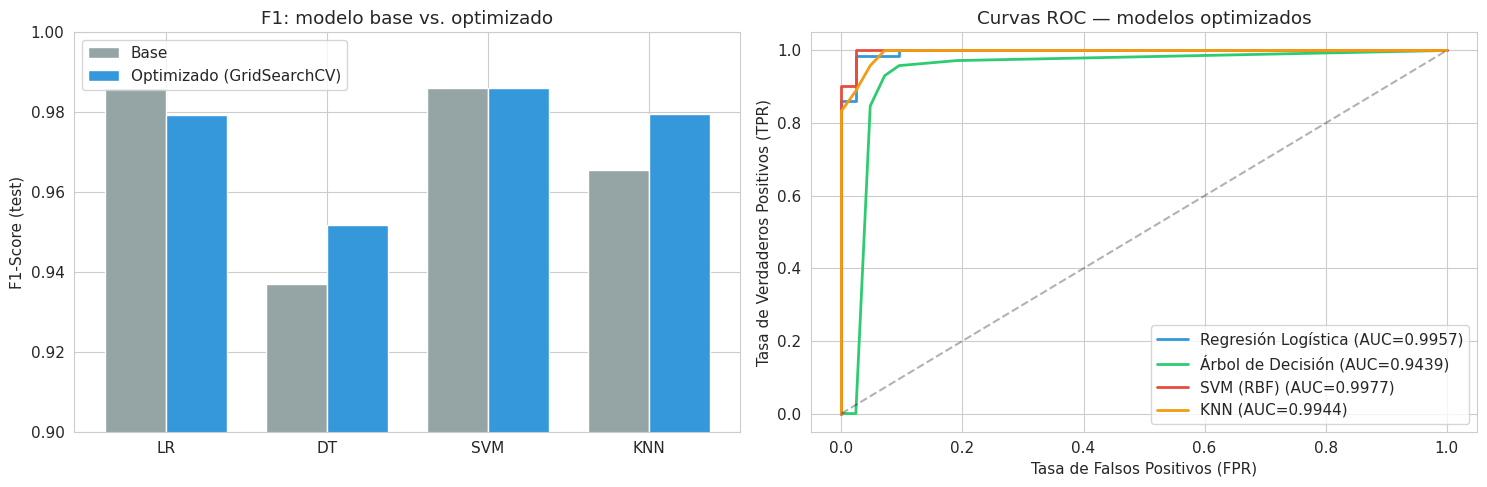

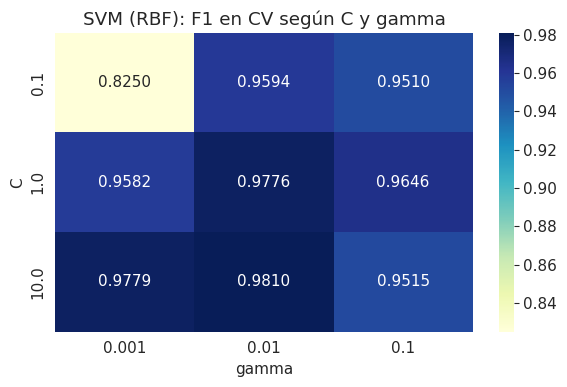

Mejor modelo optimizado por F1 en test: SVM (RBF) (F1 = 0.9861)
Mejor modelo optimizado por Recall maligno: SVM (RBF) (0.9762)


In [7]:
# E1.3  Comparación gráfica: F1 base vs optimizado y curvas ROC
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

x = np.arange(len(comp))
w = 0.38
axes[0].bar(x - w/2, comp['F1 base'], w, label='Base', color='#95a5a6')
axes[0].bar(x + w/2, comp['F1 optimizado'], w, label='Optimizado (GridSearchCV)', color='#3498db')
axes[0].set_xticks(x)
axes[0].set_xticklabels(['LR', 'DT', 'SVM', 'KNN'])
axes[0].set_ylim(0.9, 1.0)
axes[0].set_ylabel('F1-Score (test)')
axes[0].set_title('F1: modelo base vs. optimizado')
axes[0].legend()

for (name, gs), color in zip(grid_results.items(), colors_models):
    y_prob = gs.best_estimator_.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    axes[1].plot(fpr, tpr, linewidth=2, color=color,
                 label=f'{name} (AUC={auc(fpr, tpr):.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.3)
axes[1].set_xlabel('Tasa de Falsos Positivos (FPR)')
axes[1].set_ylabel('Tasa de Verdaderos Positivos (TPR)')
axes[1].set_title('Curvas ROC — modelos optimizados')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

# Mapa de calor de la grilla del SVM (C vs gamma)
cvr = pd.DataFrame(grid_results['SVM (RBF)'].cv_results_)
heat = cvr.pivot(index='param_clf__C', columns='param_clf__gamma', values='mean_test_score').astype(float)
plt.figure(figsize=(6, 4))
sns.heatmap(heat, annot=True, fmt='.4f', cmap='YlGnBu')
plt.title('SVM (RBF): F1 en CV según C y gamma')
plt.xlabel('gamma'); plt.ylabel('C')
plt.tight_layout()
plt.show()

mejor = opt_df['F1-Score'].idxmax()
print(f'Mejor modelo optimizado por F1 en test: {mejor} (F1 = {opt_df.loc[mejor, "F1-Score"]:.4f})')
print(f'Mejor modelo optimizado por Recall maligno: {opt_df["Recall maligno"].idxmax()} '
      f'({opt_df["Recall maligno"].max():.4f})')

**Conclusiones del Ejercicio 1**

- **Árbol de Decisión** y **KNN** son los que más ganan con la búsqueda: el F1 en test sube de 0.937 a 0.952 (`max_depth=3`, `min_samples_leaf=5`) y de 0.966 a 0.980 (`K=9`, pesos uniformes).
- **SVM (RBF)** mantiene su F1 (0.986) con `C=10` y `gamma=0.01`, y mejora el AUC (0.995 → 0.998).
- **Regresión Logística** tuvo el mejor F1 en validación cruzada (`C=0.1`), pero en test baja un poco (0.986 → 0.979). Es una diferencia de una sola muestra.
- **Mejor modelo optimizado: SVM (RBF)**, con F1 = 0.986 y Recall de la clase maligna = 0.976 (deja pasar 1 maligno de 42).
- Con un test de solo 114 muestras, diferencias de 1 o 2 casos no son concluyentes; conviene apoyarse también en el F1 de validación cruzada.


---
## Ejercicio 2 — Manejo de desbalance con `class_weight` y SMOTE

Se comparan tres escenarios por modelo: **sin balanceo**, **`class_weight='balanced'`** y **SMOTE**.

Puntos importantes:
- En este dataset `0 = maligno` y `1 = benigno`, así que el **Recall de la clase maligna** se calcula con `recall_score(..., pos_label=0)`. El `recall_score` por defecto mide la clase benigna.
- `KNeighborsClassifier` **no tiene** parámetro `class_weight`, por eso para KNN solo se evalúa SMOTE.
- SMOTE se aplica **dentro del pipeline** (`imblearn.pipeline.Pipeline`), después del escalado y solo sobre los datos de entrenamiento de cada fold, para evitar fuga de información hacia validación/test.

Antes de SMOTE : {'benigno': 285, 'maligno': 170}
Después de SMOTE: {'benigno': 285, 'maligno': 285}


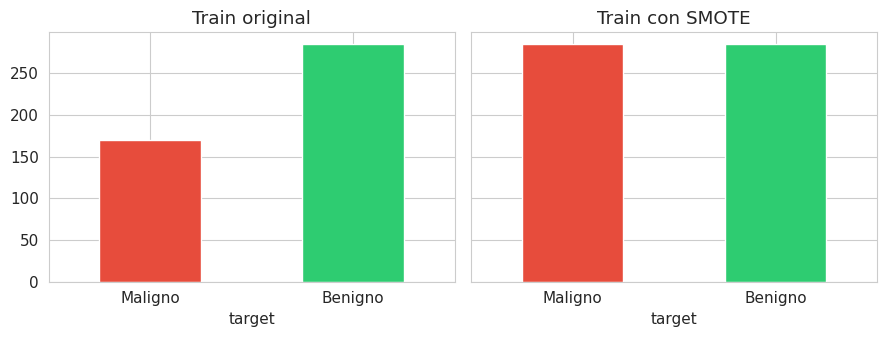

In [8]:
# E2.1  Distribución de clases y SMOTE (versión del enunciado, solo para ver el efecto)
# pip install imbalanced-learn   (en Colab: !pip install imbalanced-learn)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import make_scorer

smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_train, y_train)

print('Antes de SMOTE :', y_train.value_counts().rename({0: 'maligno', 1: 'benigno'}).to_dict())
print('Después de SMOTE:', y_res.value_counts().rename({0: 'maligno', 1: 'benigno'}).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for ax, serie, titulo in zip(axes, [y_train, y_res], ['Train original', 'Train con SMOTE']):
    serie.map({0: 'Maligno', 1: 'Benigno'}).value_counts().reindex(['Maligno', 'Benigno']).plot(
        kind='bar', ax=ax, color=['#e74c3c', '#2ecc71'])
    ax.set_title(titulo)
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

In [9]:
# E2.2  Fábrica de pipelines: sin balanceo / class_weight / SMOTE
def make_pipes(class_weight=None, use_smote=False):
    P = ImbPipeline if use_smote else Pipeline
    sm = [('smote', SMOTE(random_state=42))] if use_smote else []
    sc = [('scaler', StandardScaler())]
    return {
        'Regresión Logística': P(sc + sm + [('clf', LogisticRegression(
            max_iter=1000, class_weight=class_weight, random_state=42))]),
        'Árbol de Decisión': P((sc if use_smote else []) + sm + [('clf', DecisionTreeClassifier(
            max_depth=5, min_samples_split=10, min_samples_leaf=5,
            class_weight=class_weight, random_state=42))]),
        'SVM (RBF)': P(sc + sm + [('clf', SVC(
            kernel='rbf', C=1.0, probability=True,
            class_weight=class_weight, random_state=42))]),
        'KNN (K=5)': P(sc + sm + [('clf', KNeighborsClassifier(n_neighbors=5))]),  # sin class_weight
    }

escenarios = {
    'Sin balanceo': make_pipes(),
    'class_weight': make_pipes(class_weight='balanced'),
    'SMOTE': make_pipes(use_smote=True),
}

scorers = {
    'recall_maligno': make_scorer(recall_score, pos_label=0),
    'f1_maligno': make_scorer(f1_score, pos_label=0),
    'accuracy': 'accuracy'
}

rows = []
for esc, pipes in escenarios.items():
    for name, pipe in pipes.items():
        if esc == 'class_weight' and name == 'KNN (K=5)':
            continue  # KNN no soporta class_weight
        cv = cross_validate(pipe, X_train, y_train, cv=skf, scoring=scorers)
        pipe.fit(X_train, y_train)
        y_pred = pipe.predict(X_test)
        cm = confusion_matrix(y_test, y_pred)   # filas = real, columnas = predicción (0=maligno, 1=benigno)
        rows.append({
            'Modelo': name,
            'Escenario': esc,
            'CV Recall maligno': cv['test_recall_maligno'].mean(),
            'Test Recall maligno': recall_score(y_test, y_pred, pos_label=0),
            'Test Precision maligno': precision_score(y_test, y_pred, pos_label=0),
            'Test F1 maligno': f1_score(y_test, y_pred, pos_label=0),
            'Test Accuracy': accuracy_score(y_test, y_pred),
            'Malignos no detectados': int(cm[0, 1]),
            'Benignos marcados como malignos': int(cm[1, 0]),
        })

res2 = pd.DataFrame(rows)
print('=== Recall de la clase maligna: comparación de escenarios ===')
display(res2.pivot(index='Modelo', columns='Escenario',
                   values='Test Recall maligno')[['Sin balanceo', 'class_weight', 'SMOTE']].round(4))
print('\n=== Detalle completo ===')
display(res2.set_index(['Modelo', 'Escenario']).round(4))

=== Recall de la clase maligna: comparación de escenarios ===


Escenario,Sin balanceo,class_weight,SMOTE
Modelo,,,
KNN (K=5),0.9286,NaN,0.9286
Regresión Logística,0.9762,0.9762,0.9762
SVM (RBF),0.9762,0.9762,0.9762
Árbol de Decisión,0.9048,0.9048,0.9286



=== Detalle completo ===


,,CV Recall maligno,Test Recall maligno,Test Precision maligno,Test F1 maligno,Test Accuracy,Malignos no detectados,Benignos marcados como malignos
Modelo,Escenario,,,,,,,
Regresión Logística,Sin balanceo,0.9647,0.9762,0.9762,0.9762,0.9825,1,1
Árbol de Decisión,Sin balanceo,0.9118,0.9048,0.8837,0.8941,0.9211,4,5
SVM (RBF),Sin balanceo,0.9529,0.9762,0.9762,0.9762,0.9825,1,1
KNN (K=5),Sin balanceo,0.9294,0.9286,0.9512,0.9398,0.9561,3,2
Regresión Logística,class_weight,0.9765,0.9762,0.9111,0.9425,0.9561,1,4
Árbol de Decisión,class_weight,0.9118,0.9048,0.8636,0.8837,0.9123,4,6
SVM (RBF),class_weight,0.9706,0.9762,0.9318,0.9535,0.9649,1,3
Regresión Logística,SMOTE,0.9706,0.9762,0.9318,0.9535,0.9649,1,3
Árbol de Decisión,SMOTE,0.9059,0.9286,0.9070,0.9176,0.9386,3,4


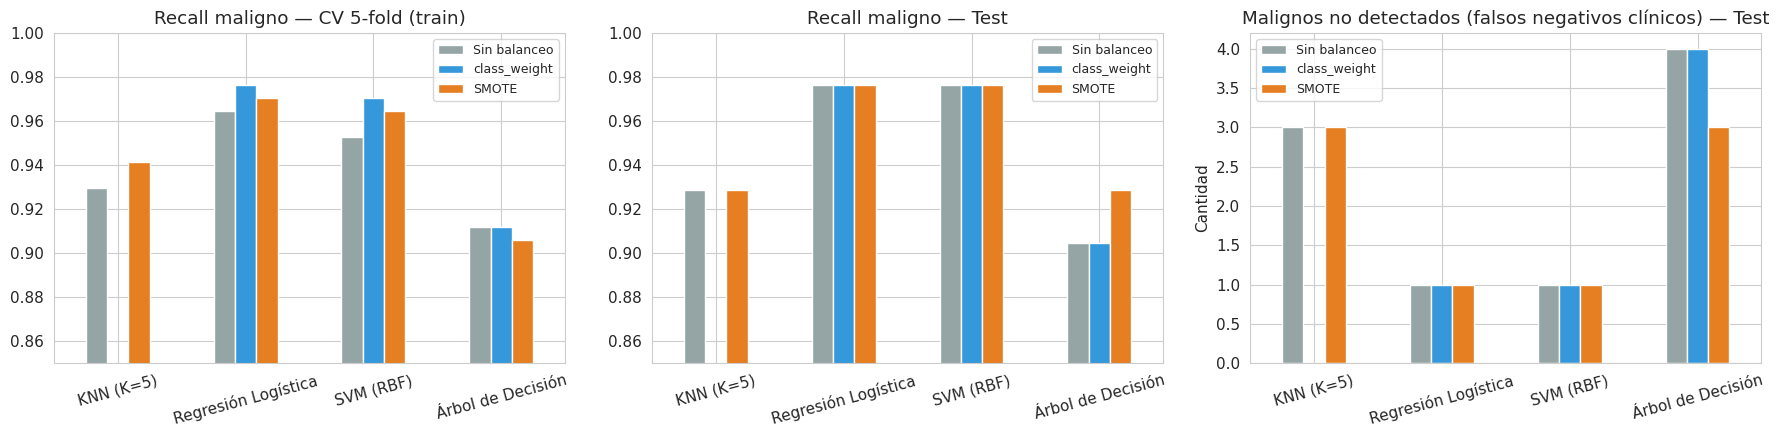

Cambio del Recall maligno en test respecto a "Sin balanceo":
  KNN (K=5)            SMOTE       : +0.0000
  Regresión Logística  class_weight: +0.0000
  Regresión Logística  SMOTE       : +0.0000
  SVM (RBF)            class_weight: +0.0000
  SVM (RBF)            SMOTE       : +0.0000
  Árbol de Decisión    class_weight: +0.0000
  Árbol de Decisión    SMOTE       : +0.0238


In [10]:
# E2.3  Gráficos comparativos
orden = ['Sin balanceo', 'class_weight', 'SMOTE']
pv_test = res2.pivot(index='Modelo', columns='Escenario', values='Test Recall maligno')[orden]
pv_fn = res2.pivot(index='Modelo', columns='Escenario', values='Malignos no detectados')[orden]
pv_cv = res2.pivot(index='Modelo', columns='Escenario', values='CV Recall maligno')[orden]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
pal = ['#95a5a6', '#3498db', '#e67e22']
pv_cv.plot(kind='bar', ax=axes[0], color=pal, rot=15)
axes[0].set_title('Recall maligno — CV 5-fold (train)')
axes[0].set_ylim(0.85, 1.0)
pv_test.plot(kind='bar', ax=axes[1], color=pal, rot=15)
axes[1].set_title('Recall maligno — Test')
axes[1].set_ylim(0.85, 1.0)
pv_fn.plot(kind='bar', ax=axes[2], color=pal, rot=15)
axes[2].set_title('Malignos no detectados (falsos negativos clínicos) — Test')
axes[2].set_ylabel('Cantidad')
for ax in axes:
    ax.set_xlabel('')
    ax.legend(title='', fontsize=9)
plt.tight_layout()
plt.show()

print('Cambio del Recall maligno en test respecto a "Sin balanceo":')
for name in pv_test.index:
    base = pv_test.loc[name, 'Sin balanceo']
    for esc in ['class_weight', 'SMOTE']:
        val = pv_test.loc[name, esc]
        if pd.notna(val):
            print(f'  {name:20s} {esc:12s}: {val - base:+.4f}')

**Conclusiones del Ejercicio 2**

- El Recall de la clase maligna en test **casi no cambia**: Regresión Logística y SVM se quedan en 0.976 y KNN en 0.929. Solo el Árbol de Decisión con SMOTE sube (0.905 → 0.929), es decir, detecta 1 maligno más.
- En validación cruzada sí hay una mejora pequeña con `class_weight` en Regresión Logística (0.965 → 0.977) y SVM (0.953 → 0.971), y con SMOTE en KNN (0.929 → 0.941).
- **Costo:** al favorecer a la clase maligna aumentan los falsos positivos (benignos marcados como malignos): por ejemplo, Regresión Logística pasa de 1 a 4 con `class_weight` y KNN de 2 a 6 con SMOTE. La accuracy y la precisión bajan.
- La razón es que el desbalance es **moderado** (63 % benigno / 37 % maligno). Estas técnicas rinden más con desbalances fuertes (por ejemplo 95/5).
- En un contexto médico puede valer la pena aceptar más falsos positivos para no perder casos malignos, pero aquí la ganancia es muy pequeña frente al costo.
- KNN no admite `class_weight`, por eso solo se evaluó con SMOTE.


---
## Ejercicio 3 — Dataset propio: *Sleep Debt & Screen Time* (Kaggle)

**Problema de clasificación binaria:** predecir si una persona termina con **deuda de sueño** (clase 1) o con **sueño suficiente** (clase 0) usando solo lo que se sabe **antes de dormir**.

| Categoría original (`sleep_debt_category`) | Horas de sueño | Clase binaria |
|---|---|---|
| Optimal Recovery | ≥ 7.75 h | 0 — Sueño suficiente |
| Mild Deficit | 6.75 – 7.74 h | 0 — Sueño suficiente |
| Moderate Debt | < 6.75 h | 1 — Deuda de sueño |
| Severe Sleep Debt | < 5.4 h (y cansancio alto) | 1 — Deuda de sueño |

**Decisiones de preparación de datos**
- **Features usadas (10):** `age`, `gender`, `occupation_type`, `chronotype`, `bedtime_phone_minutes`, `primary_bedtime_app`, `screen_brightness_pct`, `blue_light_filter_active`, `caffeine_post_5pm_mg`, `physical_activity_min`.
- **Se excluyen** `total_sleep_hours`, `deep_sleep_pct`, `rem_sleep_pct`, `sleep_latency_min`, `morning_alarm_snoozes` y `next_day_fatigue_score`: se miden **durante o después** del sueño y la categoría se define directamente con las horas de sueño. Usarlas sería **fuga de información** (el modelo "vería" la respuesta). También se elimina `user_id` (identificador).
- Las variables categóricas se codifican con one-hot.

In [13]:
import io
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

URLS = [
    # Copia pública del CSV de Kaggle en GitHub (raw, fijada a un commit)
    'https://raw.githubusercontent.com/dlmngoc817-dev/bedtime-phone-sleep-analysis/'
    'a26cfc7f64dfd0f9ab1ad3fa32f540ac86cb9fee/data.csv',
    # API de descarga de Kaggle (devuelve un .zip con el CSV)
    'https://www.kaggle.com/api/v1/datasets/download/samartalwar/sleep-debt-and-screen-time-late-night-phone-habits',
]

def cargar_desde_url(url):
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    if r.content[:2] == b'PK':                       # es un .zip
        z = zipfile.ZipFile(io.BytesIO(r.content))
        csv = [f for f in z.namelist() if f.lower().endswith('.csv')][0]
        return pd.read_csv(z.open(csv))
    return pd.read_csv(io.BytesIO(r.content))

df_s = None
for url in URLS:
    try:
        df_s = cargar_desde_url(url)
        break
    except Exception as e:
        print(f'✗ No se pudo leer {url}\n  ({type(e).__name__}: {e})')

if df_s is None:
    raise RuntimeError('No se pudo descargar el dataset desde ninguna URL.')

print(f'\nDataset: {df_s.shape[0]} filas, {df_s.shape[1]} columnas')
print(f'Valores nulos totales: {int(df_s.isna().sum().sum())}')
df_s.head()


Dataset: 8500 filas, 18 columnas
Valores nulos totales: 0


,user_id,age,gender,occupation_type,chronotype,bedtime_phone_minutes,primary_bedtime_app,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min,sleep_latency_min,total_sleep_hours,deep_sleep_pct,rem_sleep_pct,morning_alarm_snoozes,next_day_fatigue_score,sleep_debt_category
0,USR-00001,29,Female,Healthcare / Shift Worker,Intermediate,179,Instagram / Reddit,54,1,0,21,84.4,3.20,23.5,22.2,7,10.0,Severe Sleep Debt
1,USR-00002,58,Female,Student,Intermediate,163,YouTube,76,1,92,72,86.7,4.06,18.0,21.5,7,10.0,Severe Sleep Debt
2,USR-00003,41,Female,Healthcare / Shift Worker,Night Owl,100,TikTok / Reels,59,0,45,23,70.5,3.20,18.1,20.5,7,10.0,Severe Sleep Debt
3,USR-00004,36,Non-Binary,Remote Tech,Intermediate,34,YouTube,52,0,97,49,38.1,6.99,21.6,22.4,1,1.7,Mild Deficit
4,USR-00005,23,Female,Healthcare / Shift Worker,Intermediate,27,TikTok / Reels,82,1,0,38,32.3,4.58,24.1,22.8,4,5.3,Moderate Debt


In [14]:
# E3.2  Variable objetivo y selección de features
df_s['target'] = df_s['sleep_debt_category'].isin(['Moderate Debt', 'Severe Sleep Debt']).astype(int)
df_s['clase'] = df_s['target'].map({0: 'Sueño suficiente', 1: 'Deuda de sueño'})
clases_s = ['Sueño suficiente', 'Deuda de sueño']

print('Categorías originales:')
print(df_s['sleep_debt_category'].value_counts())
print('\nDistribución de clases (binaria):')
print(df_s['clase'].value_counts())
print(f'\nProporción: {df_s["target"].mean():.1%} con deuda, {1 - df_s["target"].mean():.1%} sin deuda')

num_cols_s = ['age', 'bedtime_phone_minutes', 'screen_brightness_pct',
              'blue_light_filter_active', 'caffeine_post_5pm_mg', 'physical_activity_min']
cat_cols_s = ['gender', 'occupation_type', 'chronotype', 'primary_bedtime_app']

df_s[num_cols_s].describe().round(2)

Categorías originales:
sleep_debt_category
Moderate Debt        4462
Mild Deficit         2004
Optimal Recovery     1387
Severe Sleep Debt     647
Name: count, dtype: int64

Distribución de clases (binaria):
clase
Deuda de sueño      5109
Sueño suficiente    3391
Name: count, dtype: int64

Proporción: 60.1% con deuda, 39.9% sin deuda


,age,bedtime_phone_minutes,screen_brightness_pct,blue_light_filter_active,caffeine_post_5pm_mg,physical_activity_min
count,8500.00,8500.00,8500.00,8500.00,8500.00,8500.00
mean,34.36,59.25,55.15,0.47,33.22,35.70
std,11.58,36.93,19.85,0.50,51.94,20.82
min,18.00,1.00,10.00,0.00,0.00,0.00
25%,25.00,31.00,42.00,0.00,0.00,21.00
50%,32.00,51.00,55.00,0.00,0.00,35.00
75%,42.00,79.00,69.00,1.00,55.00,50.00
max,65.00,180.00,100.00,1.00,250.00,112.00


### Análisis exploratorio orientado a clasificación

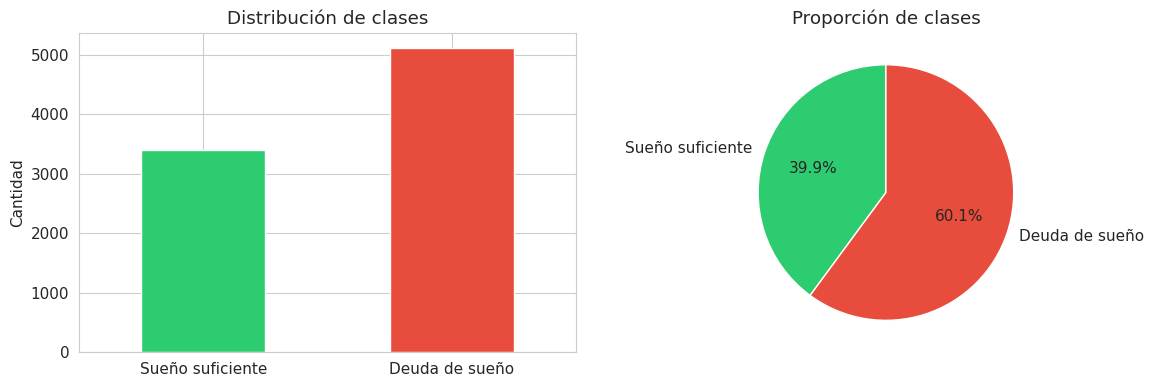

In [15]:
# E3.3  Distribución de clases
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors_s = ['#2ecc71', '#e74c3c']          # 0 = sueño suficiente, 1 = deuda de sueño

conteo = df_s['clase'].value_counts().reindex(clases_s)
conteo.plot(kind='bar', ax=axes[0], color=colors_s, rot=0)
axes[0].set_title('Distribución de clases')
axes[0].set_ylabel('Cantidad')
axes[0].set_xlabel('')

conteo.plot(kind='pie', ax=axes[1], colors=colors_s, autopct='%1.1f%%', startangle=90)
axes[1].set_ylabel('')
axes[1].set_title('Proporción de clases')

plt.tight_layout()
plt.show()

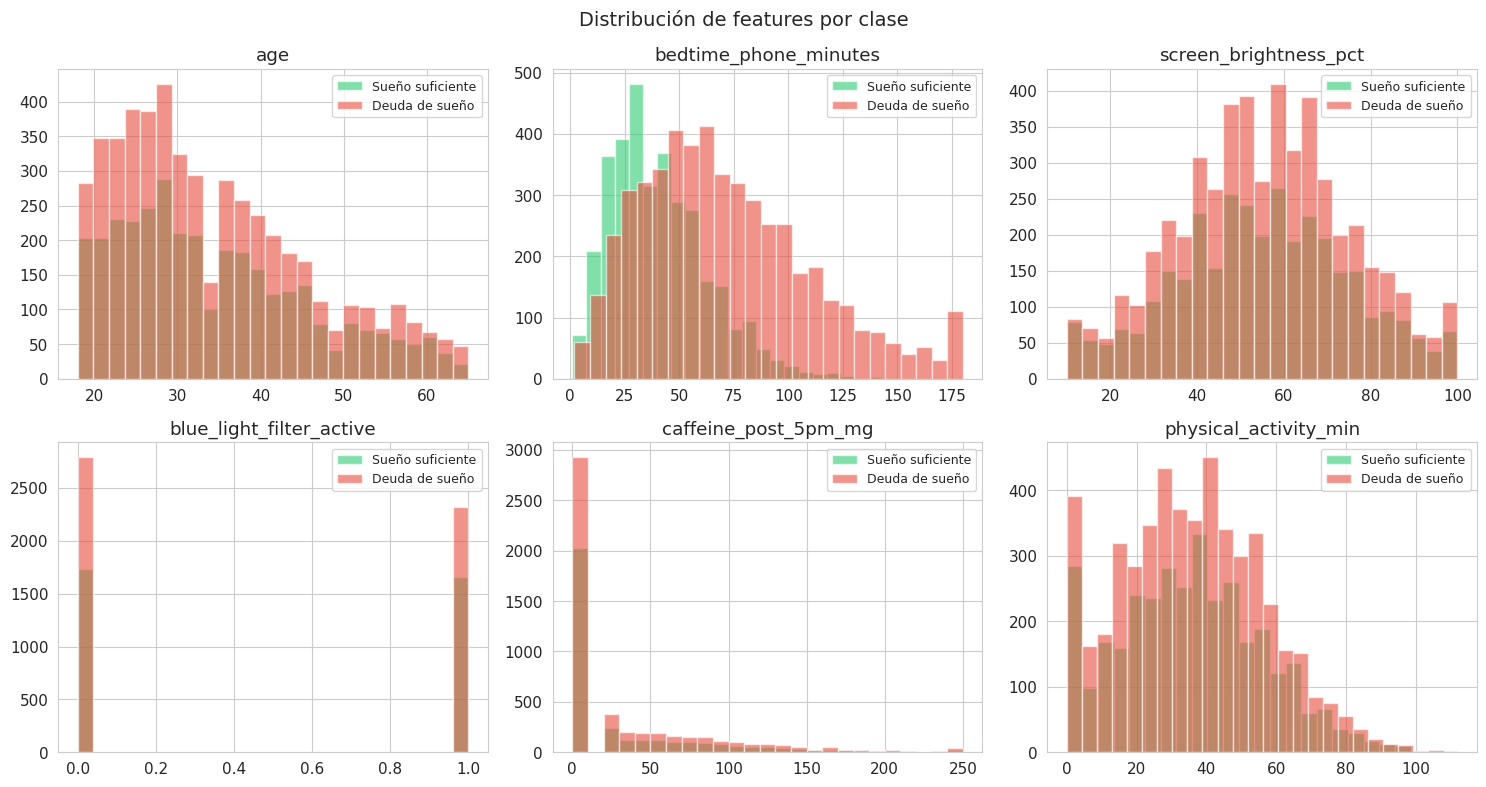

In [16]:
# E3.4  Distribución de features numéricas por clase
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, feat in enumerate(num_cols_s):
    ax = axes[i // 3, i % 3]
    for label, color in zip([0, 1], colors_s):
        subset = df_s[df_s['target'] == label][feat]
        ax.hist(subset, bins=25, alpha=0.6, color=color, label=clases_s[label])
    ax.set_title(feat)
    ax.legend(fontsize=9)

plt.suptitle('Distribución de features por clase', fontsize=14)
plt.tight_layout()
plt.show()

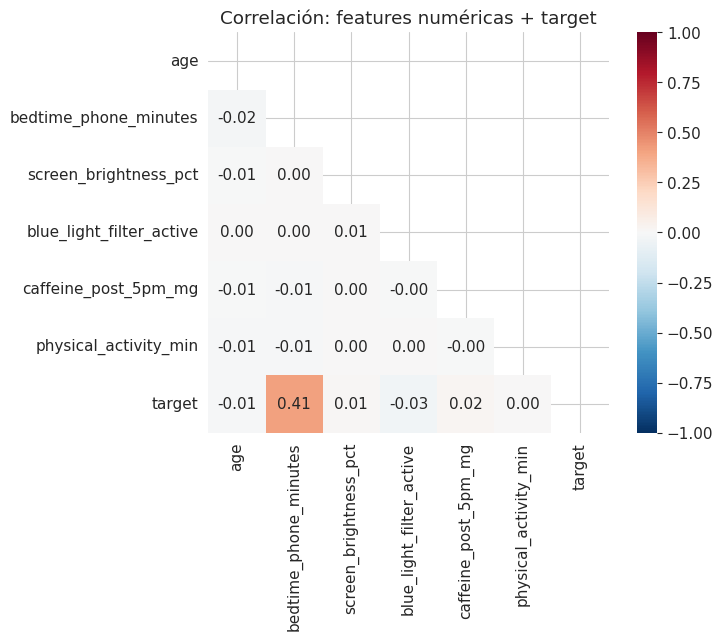

In [17]:
# E3.5  Matriz de correlación (features numéricas + target)
plt.figure(figsize=(8, 6.5))
corr_s = df_s[num_cols_s + ['target']].corr()
mask = np.triu(np.ones_like(corr_s, dtype=bool))
sns.heatmap(corr_s, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True)
plt.title('Correlación: features numéricas + target')
plt.tight_layout()
plt.show()

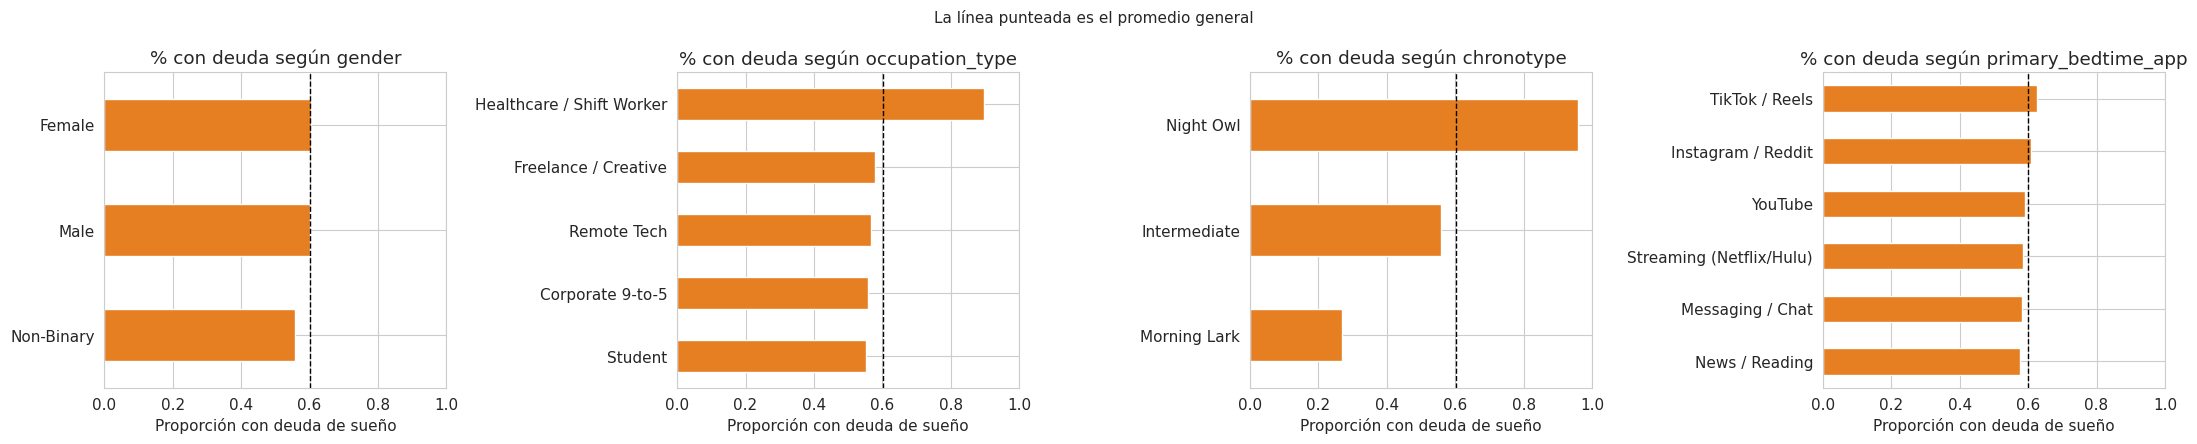

In [18]:
# E3.6  Porcentaje con deuda de sueño según variables categóricas
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for ax, col in zip(axes, cat_cols_s):
    tasa = df_s.groupby(col)['target'].mean().sort_values()
    tasa.plot(kind='barh', ax=ax, color='#e67e22')
    ax.axvline(df_s['target'].mean(), color='black', linestyle='--', linewidth=1)
    ax.set_title(f'% con deuda según {col}')
    ax.set_xlabel('Proporción con deuda de sueño')
    ax.set_ylabel('')
    ax.set_xlim(0, 1)
plt.suptitle('La línea punteada es el promedio general', fontsize=11)
plt.tight_layout()
plt.show()

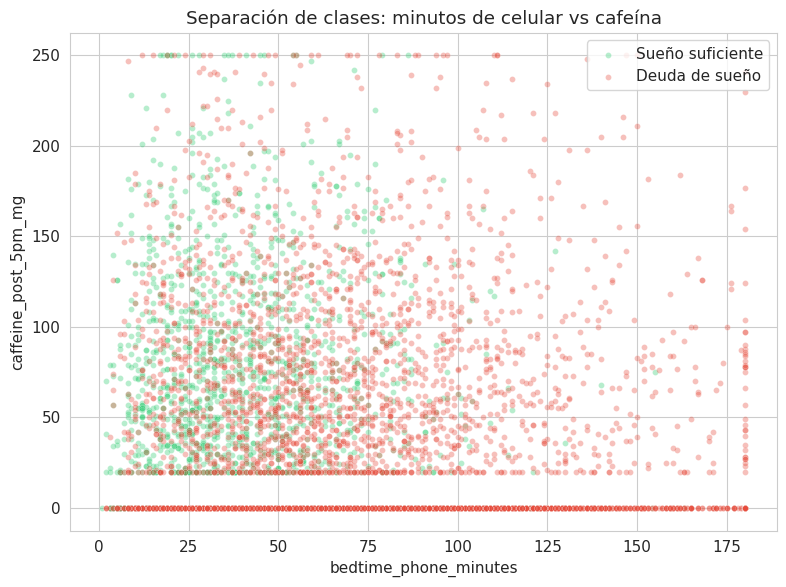

In [19]:
# E3.7  Scatter: minutos de celular antes de dormir vs cafeína después de las 5 p. m.
fig, ax = plt.subplots(figsize=(8, 6))
for label, color in zip([0, 1], colors_s):
    m = df_s['target'] == label
    ax.scatter(df_s.loc[m, 'bedtime_phone_minutes'], df_s.loc[m, 'caffeine_post_5pm_mg'],
               alpha=0.35, c=color, label=clases_s[label], edgecolors='w', linewidth=0.3, s=18)
ax.set_xlabel('bedtime_phone_minutes')
ax.set_ylabel('caffeine_post_5pm_mg')
ax.set_title('Separación de clases: minutos de celular vs cafeína')
ax.legend()
plt.tight_layout()
plt.show()

### Preparación de datos

In [20]:
# E3.8  Matriz de features, partición train/test y validación cruzada
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

X_s = pd.concat([df_s[num_cols_s],
                 pd.get_dummies(df_s[cat_cols_s], dtype=int)], axis=1)
y_s = df_s['target'].copy()
feature_names_s = X_s.columns.tolist()

Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_s, y_s, test_size=0.2, random_state=42, stratify=y_s
)

print(f'Matriz de features: {X_s.shape[0]} muestras x {X_s.shape[1]} features (tras one-hot)')
print(f'Entrenamiento: {Xs_train.shape[0]} muestras')
print(f'Test:          {Xs_test.shape[0]} muestras')
print(f'\nProporción con deuda en train: {ys_train.mean():.1%}')
print(f'Proporción con deuda en test:  {ys_test.mean():.1%}')

skf_s = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Matriz de features: 8500 muestras x 23 features (tras one-hot)
Entrenamiento: 6800 muestras
Test:          1700 muestras

Proporción con deuda en train: 60.1%
Proporción con deuda en test:  60.1%


In [21]:
# E3.9  Funciones auxiliares de evaluación (mismas que en el ejemplo, con las clases de este dataset)
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             precision_score, recall_score, f1_score, roc_curve, auc)

def eval_classifier_s(model, X_te, y_te, model_name='Modelo'):
    """Evalúa un clasificador: métricas, matriz de confusión y reporte."""
    y_pred = model.predict(X_te)
    metrics = {
        'Accuracy':  accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred, zero_division=0),
        'Recall':    recall_score(y_te, y_pred),
        'F1-Score':  f1_score(y_te, y_pred)
    }
    print(f'=== {model_name} ===')
    for k, v in metrics.items():
        print(f'  {k}: {v:.4f}')

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    cm = confusion_matrix(y_te, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
                xticklabels=clases_s, yticklabels=clases_s)
    axes[0].set_title(f'Matriz de Confusión — {model_name}')
    axes[0].set_xlabel('Predicción')
    axes[0].set_ylabel('Real')

    tn, fp, fn, tp = cm.ravel()
    labels = ['TN\n(sin deuda\ncorrecto)', 'FP\n(sin deuda→\ncon deuda)',
              'FN\n(con deuda→\nsin deuda)', 'TP\n(con deuda\ncorrecto)']
    axes[1].bar(labels, [tn, fp, fn, tp], color=['#2ecc71', '#f39c12', '#e74c3c', '#3498db'])
    axes[1].set_title(f'Desglose — {model_name}')
    axes[1].set_ylabel('Cantidad')
    plt.tight_layout()
    plt.show()

    print(f'\n  FN (deuda de sueño no detectada): {fn}')
    print(f'  FP (sin deuda marcado como deuda): {fp}')
    print('\nReporte completo:')
    print(classification_report(y_te, y_pred, target_names=clases_s))
    return metrics


def plot_roc_s(model, X_te, y_te, model_name='Modelo', ax=None):
    """Genera la curva ROC de un modelo."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_te)[:, 1]
    else:
        y_score = model.decision_function(X_te)
    fpr, tpr, _ = roc_curve(y_te, y_score)
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, linewidth=2, label=f'{model_name} (AUC = {roc_auc:.4f})')
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
    ax.set_xlabel('Tasa de Falsos Positivos (FPR)')
    ax.set_ylabel('Tasa de Verdaderos Positivos (TPR)')
    ax.set_title(f'Curva ROC — {model_name}')
    ax.legend()
    return roc_auc


def resumen_cv(nombre, cv):
    print(f'{nombre} — Cross-Validation (5-fold)')
    for m in ['accuracy', 'f1', 'recall']:
        print(f'  {m.capitalize():9s}: {cv["test_" + m].mean():.4f} ± {cv["test_" + m].std():.4f}')

print('✓ Funciones definidas')

✓ Funciones definidas


### Modelo 1 — Regresión Logística

In [22]:
# E3.10  Regresión Logística: CV + entrenamiento
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

pipe_lr_s = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])
cv_lr_s = cross_validate(pipe_lr_s, Xs_train, ys_train, cv=skf_s,
                         scoring=['accuracy', 'f1', 'recall'], return_train_score=True)
resumen_cv('Regresión Logística', cv_lr_s)
pipe_lr_s.fit(Xs_train, ys_train);

Regresión Logística — Cross-Validation (5-fold)
  Accuracy : 0.8691 ± 0.0050
  F1       : 0.8906 ± 0.0040
  Recall   : 0.8862 ± 0.0072


=== Regresión Logística ===
  Accuracy: 0.8576
  Precision: 0.8816
  Recall: 0.8816
  F1-Score: 0.8816


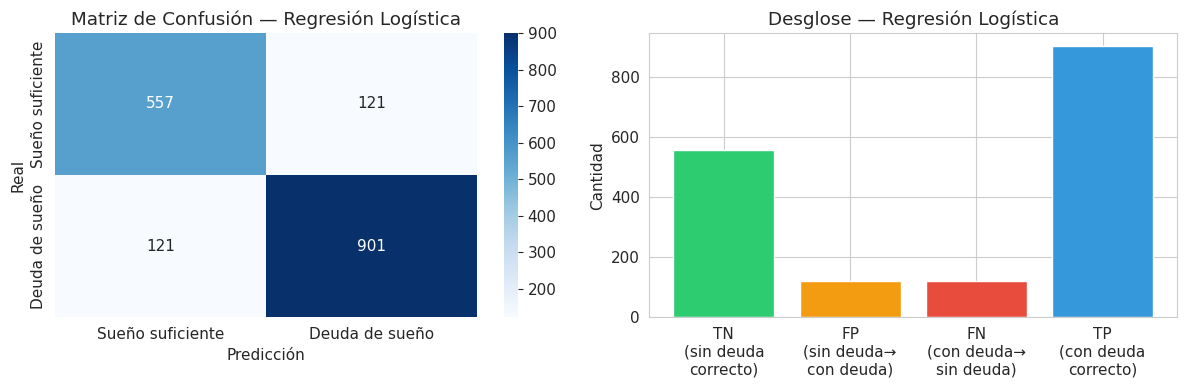


  FN (deuda de sueño no detectada): 121
  FP (sin deuda marcado como deuda): 121

Reporte completo:
                  precision    recall  f1-score   support

Sueño suficiente       0.82      0.82      0.82       678
  Deuda de sueño       0.88      0.88      0.88      1022

        accuracy                           0.86      1700
       macro avg       0.85      0.85      0.85      1700
    weighted avg       0.86      0.86      0.86      1700



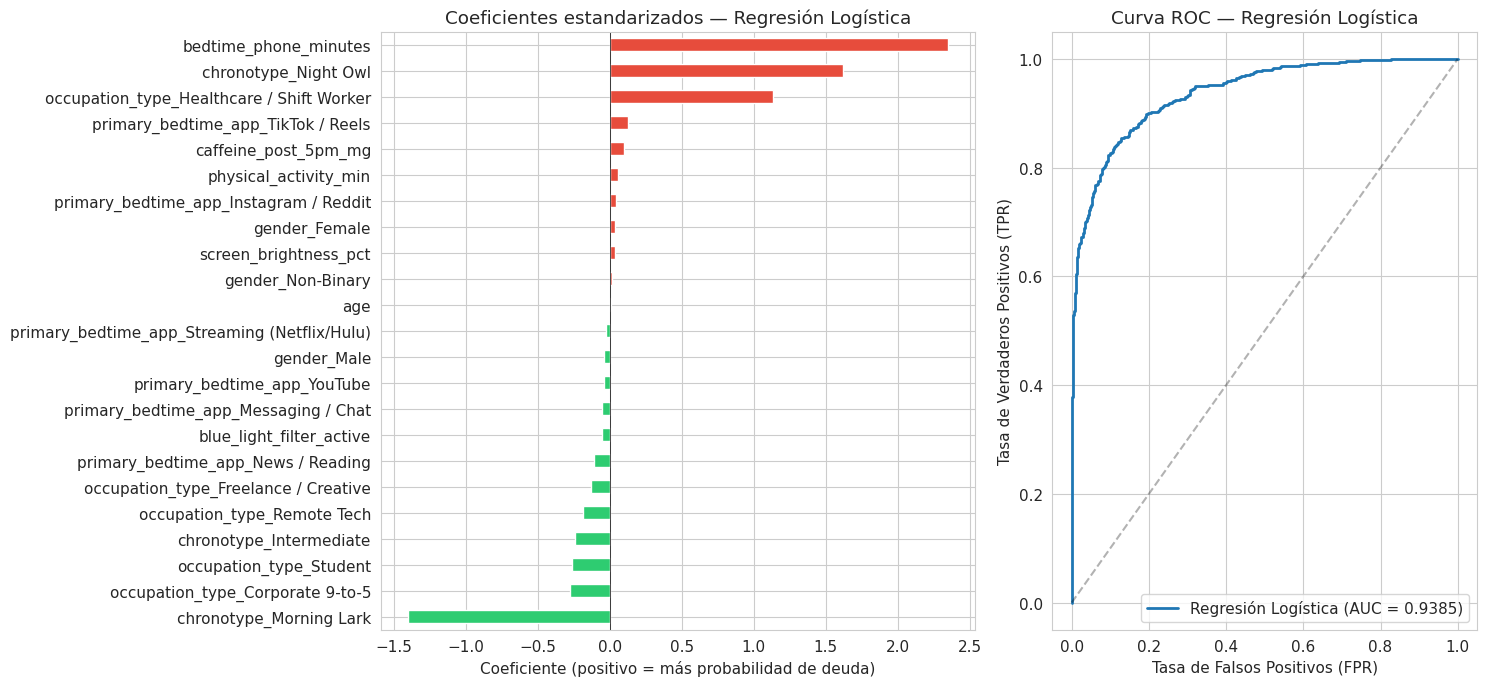

Interpretación:
  → Features que más aumentan la probabilidad de DEUDA: ['bedtime_phone_minutes', 'chronotype_Night Owl', 'occupation_type_Healthcare / Shift Worker']
  → Features que más la reducen:                        ['chronotype_Morning Lark', 'occupation_type_Corporate 9-to-5', 'occupation_type_Student']
AUC: 0.9385


In [23]:
# E3.11  Evaluación, coeficientes y curva ROC
metrics_lr_s = eval_classifier_s(pipe_lr_s, Xs_test, ys_test, 'Regresión Logística')

coefs_s = pd.Series(pipe_lr_s.named_steps['clf'].coef_[0], index=feature_names_s).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={'width_ratios': [1.4, 1]})
coefs_s.plot(kind='barh', ax=axes[0], color=['#2ecc71' if c < 0 else '#e74c3c' for c in coefs_s])
axes[0].axvline(0, color='black', linewidth=0.5)
axes[0].set_title('Coeficientes estandarizados — Regresión Logística')
axes[0].set_xlabel('Coeficiente (positivo = más probabilidad de deuda)')
auc_lr_s = plot_roc_s(pipe_lr_s, Xs_test, ys_test, 'Regresión Logística', axes[1])
plt.tight_layout()
plt.show()

print('Interpretación:')
print(f'  → Features que más aumentan la probabilidad de DEUDA: {coefs_s.tail(3).index[::-1].tolist()}')
print(f'  → Features que más la reducen:                        {coefs_s.head(3).index.tolist()}')
print(f'AUC: {auc_lr_s:.4f}')

### Modelo 2 — Árbol de Decisión

In [24]:
# E3.12  Árbol sin restricciones vs árbol con pre-poda
from sklearn.tree import DecisionTreeClassifier, plot_tree

pipe_dt_full_s = Pipeline([('clf', DecisionTreeClassifier(random_state=42))])
cv_dt_full_s = cross_validate(pipe_dt_full_s, Xs_train, ys_train, cv=skf_s,
                              scoring=['accuracy', 'f1', 'recall'], return_train_score=True)
print('Árbol de Decisión (SIN restricciones) — CV 5-fold')
print(f'  Train Accuracy: {cv_dt_full_s["train_accuracy"].mean():.4f}')
print(f'  Test Accuracy:  {cv_dt_full_s["test_accuracy"].mean():.4f} ± {cv_dt_full_s["test_accuracy"].std():.4f}')
print('  ⚠ Train accuracy ~1.0 indica sobreajuste\n')

pipe_dt_s = Pipeline([('clf', DecisionTreeClassifier(
    max_depth=5, min_samples_split=10, min_samples_leaf=5, random_state=42))])
cv_dt_s = cross_validate(pipe_dt_s, Xs_train, ys_train, cv=skf_s,
                         scoring=['accuracy', 'f1', 'recall'], return_train_score=True)
print(f'Árbol de Decisión (con pre-poda) — Train Accuracy: {cv_dt_s["train_accuracy"].mean():.4f}')
resumen_cv('Árbol de Decisión (con pre-poda)', cv_dt_s)
pipe_dt_s.fit(Xs_train, ys_train);

Árbol de Decisión (SIN restricciones) — CV 5-fold
  Train Accuracy: 1.0000
  Test Accuracy:  0.8035 ± 0.0086
  ⚠ Train accuracy ~1.0 indica sobreajuste

Árbol de Decisión (con pre-poda) — Train Accuracy: 0.8664
Árbol de Decisión (con pre-poda) — Cross-Validation (5-fold)
  Accuracy : 0.8616 ± 0.0105
  F1       : 0.8804 ± 0.0095
  Recall   : 0.8476 ± 0.0134


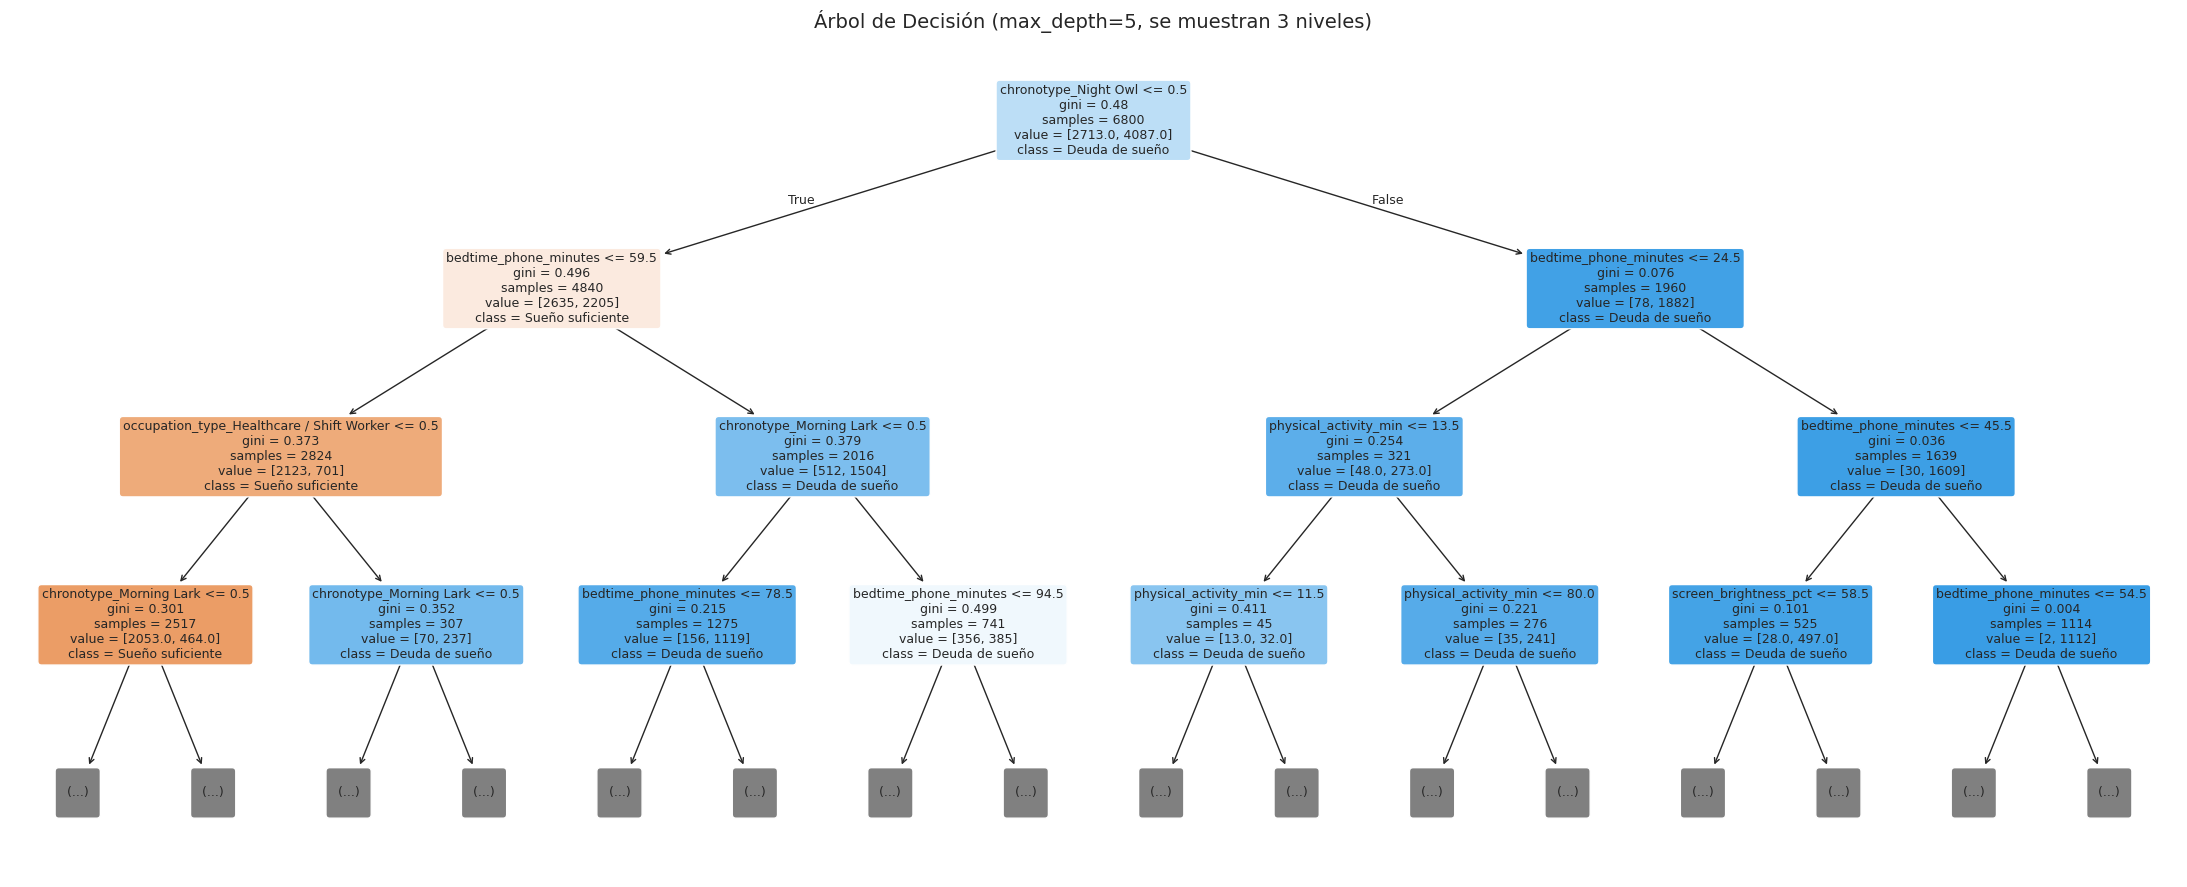

In [25]:
# E3.13  Visualización del árbol (se muestran los 3 primeros niveles para que sea legible)
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(pipe_dt_s.named_steps['clf'], feature_names=feature_names_s,
          class_names=clases_s, filled=True, rounded=True, fontsize=9, max_depth=3, ax=ax)
ax.set_title('Árbol de Decisión (max_depth=5, se muestran 3 niveles)', fontsize=14)
plt.tight_layout()
plt.show()

=== Árbol de Decisión ===
  Accuracy: 0.8588
  Precision: 0.9073
  Recall: 0.8523
  F1-Score: 0.8789


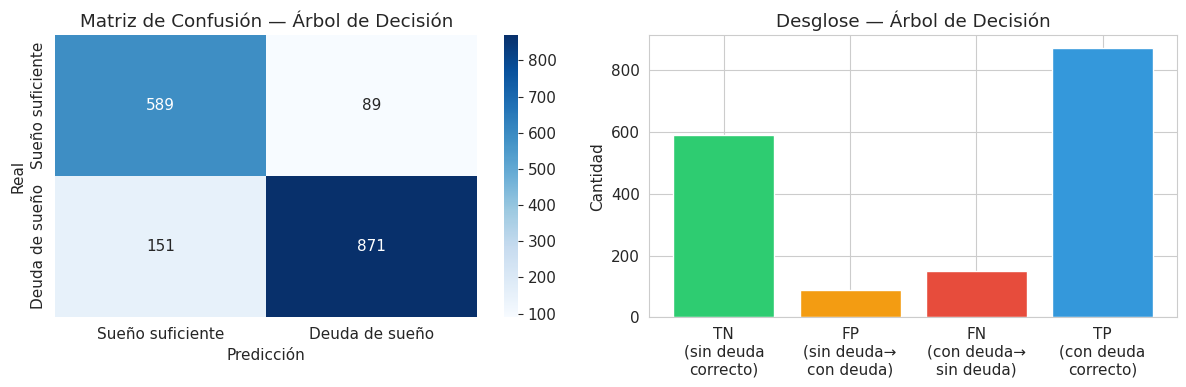


  FN (deuda de sueño no detectada): 151
  FP (sin deuda marcado como deuda): 89

Reporte completo:
                  precision    recall  f1-score   support

Sueño suficiente       0.80      0.87      0.83       678
  Deuda de sueño       0.91      0.85      0.88      1022

        accuracy                           0.86      1700
       macro avg       0.85      0.86      0.85      1700
    weighted avg       0.86      0.86      0.86      1700



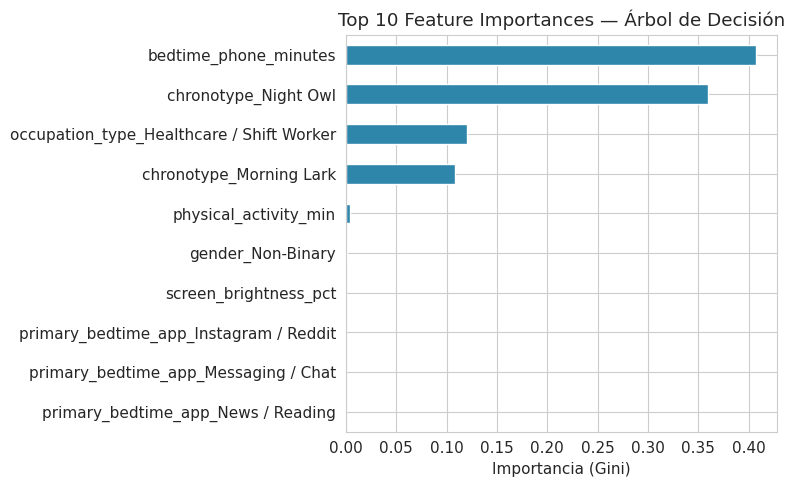

In [26]:
# E3.14  Evaluación e importancia de features
metrics_dt_s = eval_classifier_s(pipe_dt_s, Xs_test, ys_test, 'Árbol de Decisión')

imp_dt_s = pd.Series(pipe_dt_s.named_steps['clf'].feature_importances_,
                     index=feature_names_s).sort_values().tail(10)
fig, ax = plt.subplots(figsize=(8, 5))
imp_dt_s.plot(kind='barh', ax=ax, color='#2E86AB')
ax.set_title('Top 10 Feature Importances — Árbol de Decisión')
ax.set_xlabel('Importancia (Gini)')
plt.tight_layout()
plt.show()

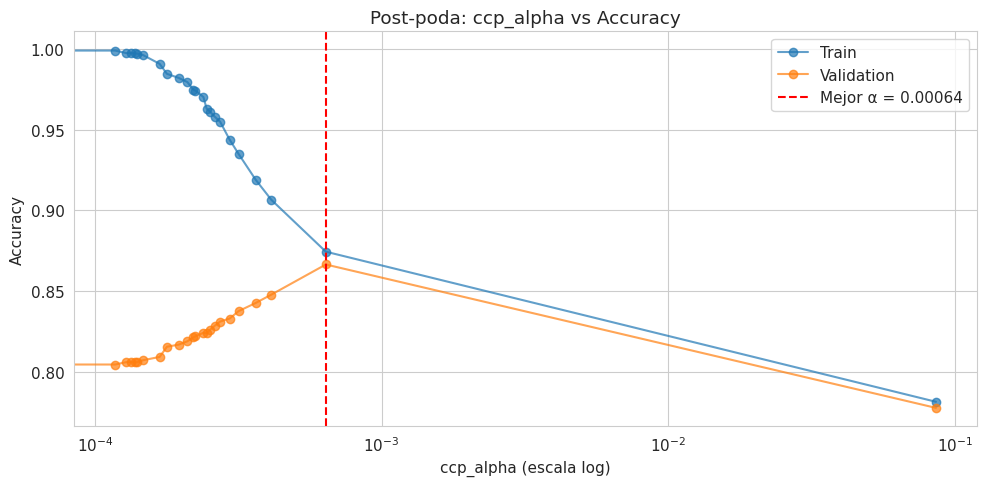

Mejor ccp_alpha: 0.000639 → Accuracy CV = 0.8665


In [27]:
# E3.15  Post-poda con ccp_alpha
# Con 6 800 filas el camino de poda tiene cientos de valores de alpha; se evalúan 25 repartidos a lo largo del camino.
path_s = DecisionTreeClassifier(random_state=42).cost_complexity_pruning_path(Xs_train, ys_train)
alphas_all = path_s.ccp_alphas[:-1]
alphas_s = np.unique(alphas_all[np.linspace(0, len(alphas_all) - 1, 25).astype(int)])

train_sc, val_sc = [], []
for a in alphas_s:
    cv_a = cross_validate(DecisionTreeClassifier(ccp_alpha=a, random_state=42), Xs_train, ys_train,
                          cv=skf_s, scoring='accuracy', return_train_score=True, n_jobs=-1)
    train_sc.append(cv_a['train_score'].mean())
    val_sc.append(cv_a['test_score'].mean())

best_a = alphas_s[int(np.argmax(val_sc))]
fig, ax = plt.subplots(figsize=(10, 5))
ax.semilogx(alphas_s, train_sc, 'o-', label='Train', alpha=0.7)
ax.semilogx(alphas_s, val_sc, 'o-', label='Validation', alpha=0.7)
ax.axvline(best_a, color='red', linestyle='--', label=f'Mejor α = {best_a:.5f}')
ax.set_xlabel('ccp_alpha (escala log)')
ax.set_ylabel('Accuracy')
ax.set_title('Post-poda: ccp_alpha vs Accuracy')
ax.legend()
plt.tight_layout()
plt.show()
print(f'Mejor ccp_alpha: {best_a:.6f} → Accuracy CV = {max(val_sc):.4f}')

### Modelo 3 — Support Vector Machine (SVM)

SVM (RBF, C=1.0) — Cross-Validation (5-fold)
  Accuracy : 0.8606 ± 0.0088
  F1       : 0.8827 ± 0.0068
  Recall   : 0.8728 ± 0.0040
=== SVM (RBF) ===
  Accuracy: 0.8559
  Precision: 0.8858
  Recall: 0.8728
  F1-Score: 0.8793


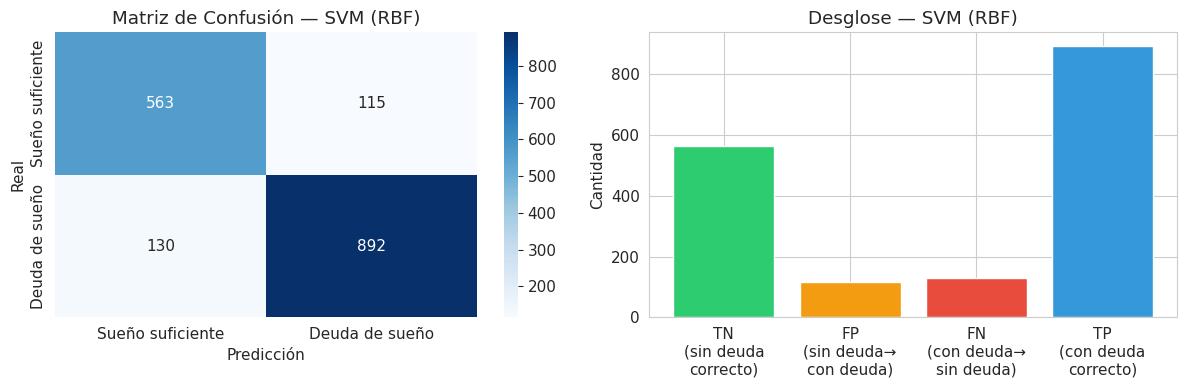


  FN (deuda de sueño no detectada): 130
  FP (sin deuda marcado como deuda): 115

Reporte completo:
                  precision    recall  f1-score   support

Sueño suficiente       0.81      0.83      0.82       678
  Deuda de sueño       0.89      0.87      0.88      1022

        accuracy                           0.86      1700
       macro avg       0.85      0.85      0.85      1700
    weighted avg       0.86      0.86      0.86      1700



In [28]:
# E3.16  SVM con kernel RBF
from sklearn.svm import SVC

pipe_svm_s = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', C=1.0, probability=True, random_state=42))
])
cv_svm_s = cross_validate(pipe_svm_s, Xs_train, ys_train, cv=skf_s,
                          scoring=['accuracy', 'f1', 'recall'], return_train_score=True, n_jobs=-1)
resumen_cv('SVM (RBF, C=1.0)', cv_svm_s)
pipe_svm_s.fit(Xs_train, ys_train)
metrics_svm_s = eval_classifier_s(pipe_svm_s, Xs_test, ys_test, 'SVM (RBF)')

  Kernel linear  : Accuracy = 0.8703
  Kernel rbf     : Accuracy = 0.8606
  Kernel poly    : Accuracy = 0.8519


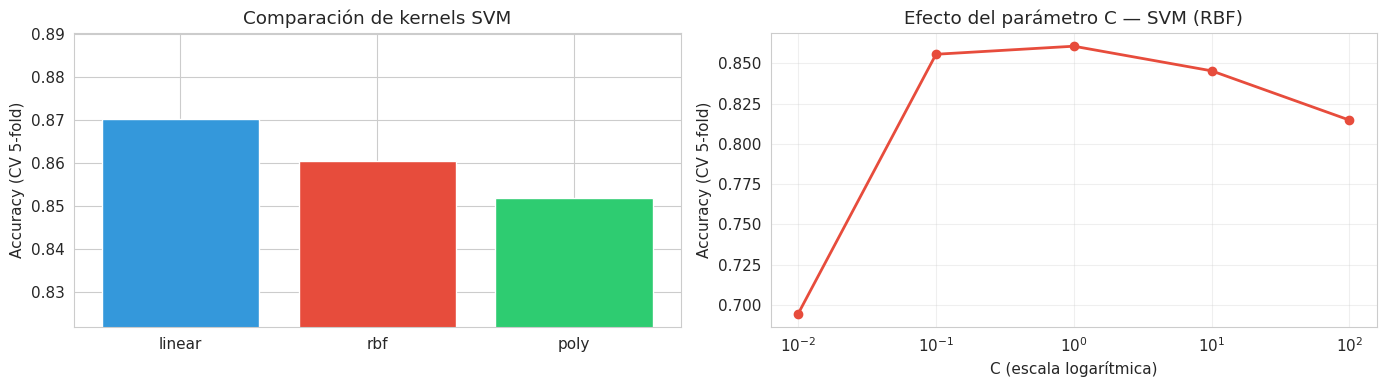


Interpretación:
  C bajo → margen amplio, más errores permitidos (mayor sesgo)
  C alto → margen estrecho, menos errores permitidos (mayor varianza)
  Mejor C en este dataset: 1


In [29]:
# E3.17  Comparación de kernels y efecto de C
kernel_res_s = {}
for k in ['linear', 'rbf', 'poly']:
    pk = Pipeline([('scaler', StandardScaler()), ('clf', SVC(kernel=k, C=1.0, random_state=42))])
    kernel_res_s[k] = cross_validate(pk, Xs_train, ys_train, cv=skf_s,
                                     scoring='accuracy', n_jobs=-1)['test_score'].mean()
    print(f'  Kernel {k:8s}: Accuracy = {kernel_res_s[k]:.4f}')

C_values_s = [0.01, 0.1, 1, 10, 100]
c_scores_s = []
for c in C_values_s:
    pc = Pipeline([('scaler', StandardScaler()), ('clf', SVC(kernel='rbf', C=c, random_state=42))])
    c_scores_s.append(cross_validate(pc, Xs_train, ys_train, cv=skf_s,
                                     scoring='accuracy', n_jobs=-1)['test_score'].mean())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(kernel_res_s.keys(), kernel_res_s.values(), color=['#3498db', '#e74c3c', '#2ecc71'])
axes[0].set_ylim(min(kernel_res_s.values()) - 0.03, max(kernel_res_s.values()) + 0.02)
axes[0].set_ylabel('Accuracy (CV 5-fold)')
axes[0].set_title('Comparación de kernels SVM')
axes[1].semilogx(C_values_s, c_scores_s, 'o-', color='#e74c3c', linewidth=2)
axes[1].set_xlabel('C (escala logarítmica)')
axes[1].set_ylabel('Accuracy (CV 5-fold)')
axes[1].set_title('Efecto del parámetro C — SVM (RBF)')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('\nInterpretación:')
print('  C bajo → margen amplio, más errores permitidos (mayor sesgo)')
print('  C alto → margen estrecho, menos errores permitidos (mayor varianza)')
print(f'  Mejor C en este dataset: {C_values_s[int(np.argmax(c_scores_s))]}')

### Modelo 4 — K-Nearest Neighbors (KNN)

KNN (K=5) — Cross-Validation (5-fold)
  Accuracy : 0.8006 ± 0.0177
  F1       : 0.8317 ± 0.0140
  Recall   : 0.8197 ± 0.0131
=== KNN (K=5) ===
  Accuracy: 0.7865
  Precision: 0.8272
  Recall: 0.8151
  F1-Score: 0.8211


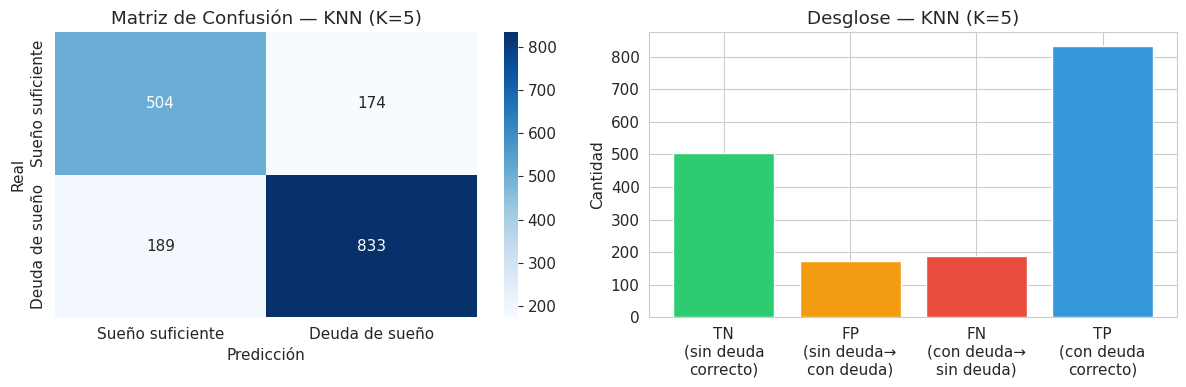


  FN (deuda de sueño no detectada): 189
  FP (sin deuda marcado como deuda): 174

Reporte completo:
                  precision    recall  f1-score   support

Sueño suficiente       0.73      0.74      0.74       678
  Deuda de sueño       0.83      0.82      0.82      1022

        accuracy                           0.79      1700
       macro avg       0.78      0.78      0.78      1700
    weighted avg       0.79      0.79      0.79      1700



In [30]:
# E3.18  KNN con K=5
from sklearn.neighbors import KNeighborsClassifier

pipe_knn_s = Pipeline([('scaler', StandardScaler()), ('clf', KNeighborsClassifier(n_neighbors=5))])
cv_knn_s = cross_validate(pipe_knn_s, Xs_train, ys_train, cv=skf_s,
                          scoring=['accuracy', 'f1', 'recall'], return_train_score=True)
resumen_cv('KNN (K=5)', cv_knn_s)
pipe_knn_s.fit(Xs_train, ys_train)
metrics_knn_s = eval_classifier_s(pipe_knn_s, Xs_test, ys_test, 'KNN (K=5)')

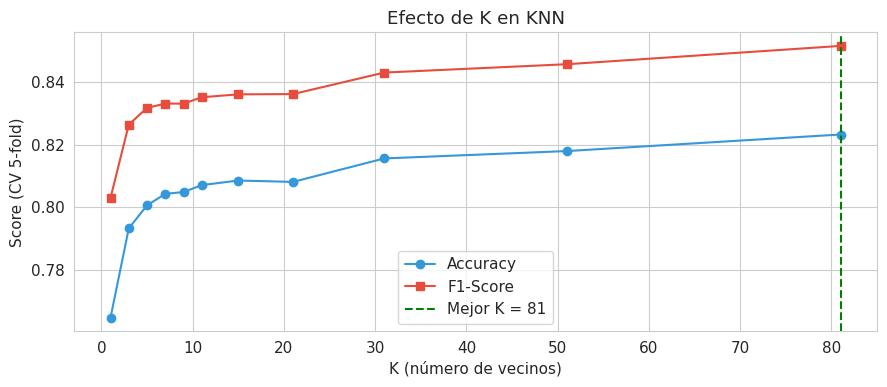

Mejor K por F1: 81 (F1 = 0.8515)
K empírico (√6800): 82

  Distancia euclidean           : F1 = 0.8317
  Distancia manhattan           : F1 = 0.8275
  Distancia minkowski (p=3)     : F1 = 0.8310


In [31]:
# E3.19  Búsqueda del K óptimo y métricas de distancia
k_values_s = [1, 3, 5, 7, 9, 11, 15, 21, 31, 51, 81]
k_acc_s, k_f1_s = [], []
for k in k_values_s:
    pk = Pipeline([('scaler', StandardScaler()), ('clf', KNeighborsClassifier(n_neighbors=k))])
    cvk = cross_validate(pk, Xs_train, ys_train, cv=skf_s, scoring=['accuracy', 'f1'], n_jobs=-1)
    k_acc_s.append(cvk['test_accuracy'].mean())
    k_f1_s.append(cvk['test_f1'].mean())

best_k_s = k_values_s[int(np.argmax(k_f1_s))]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(k_values_s, k_acc_s, 'o-', label='Accuracy', color='#3498db')
ax.plot(k_values_s, k_f1_s, 's-', label='F1-Score', color='#e74c3c')
ax.axvline(best_k_s, color='green', linestyle='--', label=f'Mejor K = {best_k_s}')
ax.set_xlabel('K (número de vecinos)')
ax.set_ylabel('Score (CV 5-fold)')
ax.set_title('Efecto de K en KNN')
ax.legend()
plt.tight_layout()
plt.show()
print(f'Mejor K por F1: {best_k_s} (F1 = {max(k_f1_s):.4f})')
print(f'K empírico (√{len(Xs_train)}): {int(np.sqrt(len(Xs_train)))}\n')

for d in ['euclidean', 'manhattan', 'minkowski']:
    p_val = 3 if d == 'minkowski' else 2
    pdd = Pipeline([('scaler', StandardScaler()),
                    ('clf', KNeighborsClassifier(n_neighbors=5, metric=d, p=p_val))])
    f1d = cross_validate(pdd, Xs_train, ys_train, cv=skf_s, scoring='f1', n_jobs=-1)['test_score'].mean()
    label = f'{d} (p={p_val})' if d == 'minkowski' else d
    print(f'  Distancia {label:20s}: F1 = {f1d:.4f}')

### Modelos adicionales — Random Forest y Gradient Boosting

**Random Forest:** conjunto de muchos árboles entrenados sobre muestras bootstrap y subconjuntos aleatorios de features; la predicción es el voto de todos. Reduce la varianza de un árbol individual.

**Gradient Boosting:** construye árboles pequeños en secuencia, donde cada uno corrige los errores (gradiente de la log-loss) de los anteriores. Suele dar muy buena precisión en datos tabulares.

Random Forest — Cross-Validation (5-fold)
  Accuracy : 0.8640 ± 0.0076
  F1       : 0.8864 ± 0.0059
  Recall   : 0.8826 ± 0.0062

Gradient Boosting — Cross-Validation (5-fold)
  Accuracy : 0.8672 ± 0.0072
  F1       : 0.8892 ± 0.0058
  Recall   : 0.8865 ± 0.0094

=== Random Forest ===
  Accuracy: 0.8594
  Precision: 0.8880
  Recall: 0.8767
  F1-Score: 0.8823


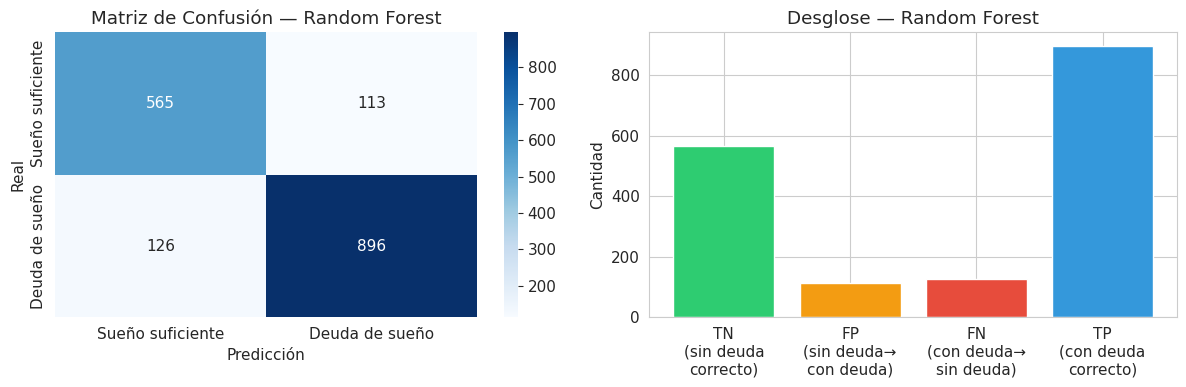


  FN (deuda de sueño no detectada): 126
  FP (sin deuda marcado como deuda): 113

Reporte completo:
                  precision    recall  f1-score   support

Sueño suficiente       0.82      0.83      0.83       678
  Deuda de sueño       0.89      0.88      0.88      1022

        accuracy                           0.86      1700
       macro avg       0.85      0.86      0.85      1700
    weighted avg       0.86      0.86      0.86      1700

=== Gradient Boosting ===
  Accuracy: 0.8618
  Precision: 0.8892
  Recall: 0.8796
  F1-Score: 0.8844


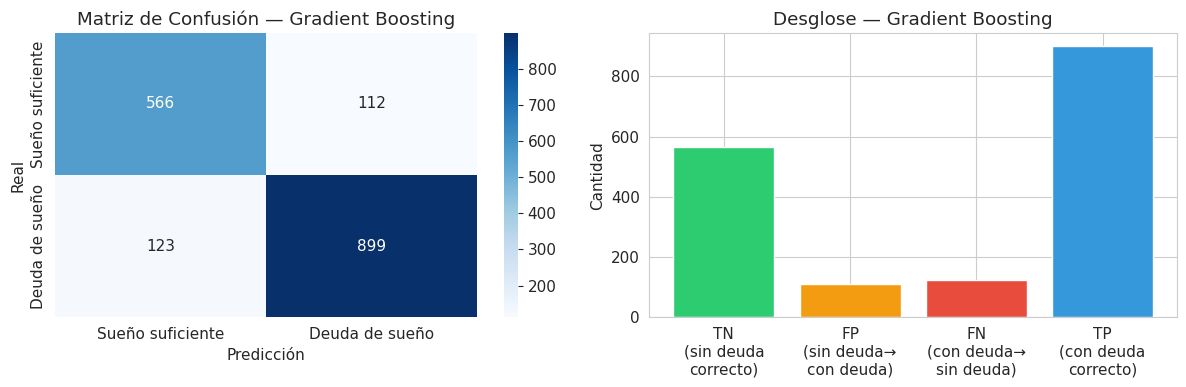


  FN (deuda de sueño no detectada): 123
  FP (sin deuda marcado como deuda): 112

Reporte completo:
                  precision    recall  f1-score   support

Sueño suficiente       0.82      0.83      0.83       678
  Deuda de sueño       0.89      0.88      0.88      1022

        accuracy                           0.86      1700
       macro avg       0.86      0.86      0.86      1700
    weighted avg       0.86      0.86      0.86      1700



In [32]:
# E3.20  Random Forest y Gradient Boosting
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

pipe_rf_s = Pipeline([('clf', RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                     random_state=42, n_jobs=-1))])
pipe_gb_s = Pipeline([('clf', GradientBoostingClassifier(random_state=42))])

for nombre, pipe in [('Random Forest', pipe_rf_s), ('Gradient Boosting', pipe_gb_s)]:
    cv_e = cross_validate(pipe, Xs_train, ys_train, cv=skf_s,
                          scoring=['accuracy', 'f1', 'recall'], return_train_score=True)
    resumen_cv(nombre, cv_e)
    print()
    pipe.fit(Xs_train, ys_train)

metrics_rf_s = eval_classifier_s(pipe_rf_s, Xs_test, ys_test, 'Random Forest')
metrics_gb_s = eval_classifier_s(pipe_gb_s, Xs_test, ys_test, 'Gradient Boosting')

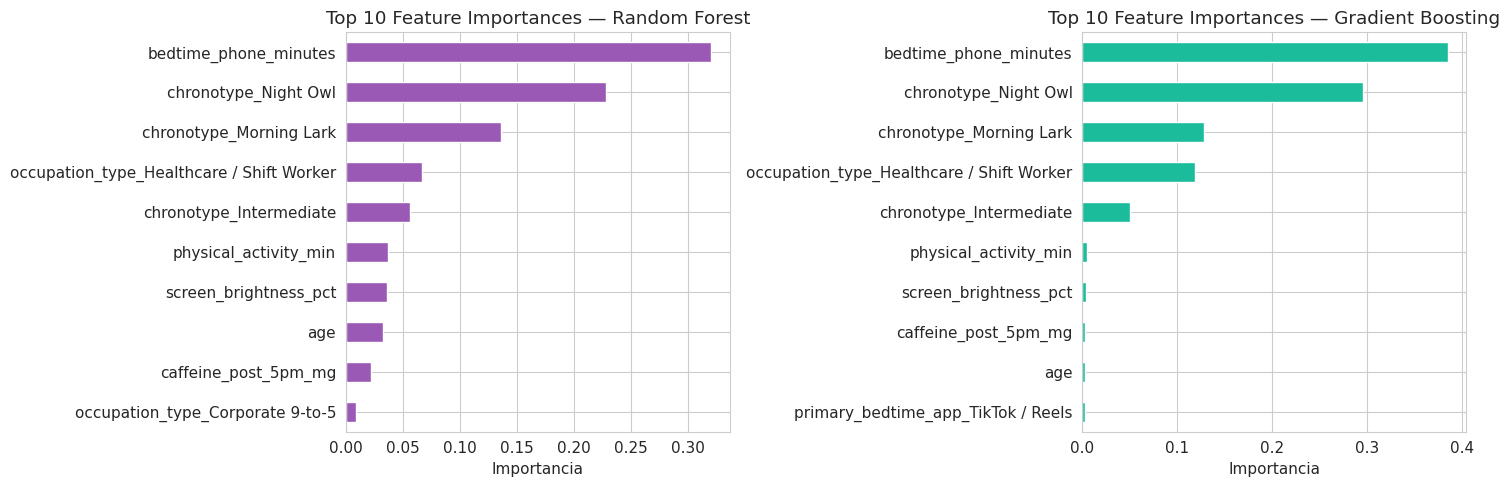

In [33]:
# E3.21  Importancia de features — Random Forest vs Gradient Boosting
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (nombre, pipe), color in zip(axes, [('Random Forest', pipe_rf_s), ('Gradient Boosting', pipe_gb_s)],
                                     ['#9b59b6', '#1abc9c']):
    imp = pd.Series(pipe.named_steps['clf'].feature_importances_,
                    index=feature_names_s).sort_values().tail(10)
    imp.plot(kind='barh', ax=ax, color=color)
    ax.set_title(f'Top 10 Feature Importances — {nombre}')
    ax.set_xlabel('Importancia')
plt.tight_layout()
plt.show()

### Comparación final de modelos

In [34]:
# E3.22  Validación cruzada de los 6 modelos con las mismas métricas (incluye AUC y tiempo)
import time
all_models_s = {
    'Regresión Logística': pipe_lr_s,
    'Árbol de Decisión':   pipe_dt_s,
    'SVM (RBF)':           pipe_svm_s,
    'KNN (K=5)':           pipe_knn_s,
    'Random Forest':       pipe_rf_s,
    'Gradient Boosting':   pipe_gb_s,
}
scoring_s = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
cv_rows_s, tiempos_s = [], {}
for name, model in all_models_s.items():
    cv = cross_validate(model, Xs_train, ys_train, cv=skf_s, scoring=scoring_s)
    tiempos_s[name] = (cv['fit_time'] + cv['score_time']).mean()
    fila = {'Modelo': name}
    for m in scoring_s:
        fila[m] = f'{cv["test_" + m].mean():.3f} ± {cv["test_" + m].std():.3f}'
    fila['_f1'] = cv['test_f1'].mean()
    fila['_auc'] = cv['test_roc_auc'].mean()
    cv_rows_s.append(fila)

cv_df_s = pd.DataFrame(cv_rows_s).set_index('Modelo')
print('=== Validación cruzada (5-fold, sobre train) ===')
display(cv_df_s.drop(columns=['_f1', '_auc']))

=== Validación cruzada (5-fold, sobre train) ===


,accuracy,precision,recall,f1,roc_auc
Modelo,,,,,
Regresión Logística,0.869 ± 0.005,0.895 ± 0.008,0.886 ± 0.007,0.891 ± 0.004,0.942 ± 0.006
Árbol de Decisión,0.862 ± 0.011,0.916 ± 0.010,0.848 ± 0.013,0.880 ± 0.009,0.933 ± 0.006
SVM (RBF),0.861 ± 0.009,0.893 ± 0.011,0.873 ± 0.004,0.883 ± 0.007,0.934 ± 0.007
KNN (K=5),0.801 ± 0.018,0.844 ± 0.020,0.820 ± 0.013,0.832 ± 0.014,0.868 ± 0.012
Random Forest,0.864 ± 0.008,0.890 ± 0.010,0.883 ± 0.006,0.886 ± 0.006,0.935 ± 0.006
Gradient Boosting,0.867 ± 0.007,0.892 ± 0.010,0.886 ± 0.009,0.889 ± 0.006,0.940 ± 0.006


In [35]:
# E3.23  Tabla resumen de métricas en test
all_metrics_s = {}
for name, model in all_models_s.items():
    y_pred = model.predict(Xs_test)
    y_prob = model.predict_proba(Xs_test)[:, 1]
    fpr, tpr, _ = roc_curve(ys_test, y_prob)
    all_metrics_s[name] = {
        'Accuracy':  accuracy_score(ys_test, y_pred),
        'Precision': precision_score(ys_test, y_pred),
        'Recall':    recall_score(ys_test, y_pred),
        'F1-Score':  f1_score(ys_test, y_pred),
        'AUC':       auc(fpr, tpr),
        'FN (deuda no detectada)': int(((ys_test == 1) & (y_pred == 0)).sum()),
    }
metrics_df_s = pd.DataFrame(all_metrics_s).T
metrics_df_s['FN (deuda no detectada)'] = metrics_df_s['FN (deuda no detectada)'].astype(int)
print('=== Tabla comparativa de métricas (Test Set) ===')
display(metrics_df_s.round(4))

=== Tabla comparativa de métricas (Test Set) ===


,Accuracy,Precision,Recall,F1-Score,AUC,FN (deuda no detectada)
Regresión Logística,0.8576,0.8816,0.8816,0.8816,0.9385,121
Árbol de Decisión,0.8588,0.9073,0.8523,0.8789,0.9301,151
SVM (RBF),0.8559,0.8858,0.8728,0.8793,0.9313,130
KNN (K=5),0.7865,0.8272,0.8151,0.8211,0.8612,189
Random Forest,0.8594,0.8880,0.8767,0.8823,0.9296,126
Gradient Boosting,0.8618,0.8892,0.8796,0.8844,0.9382,123


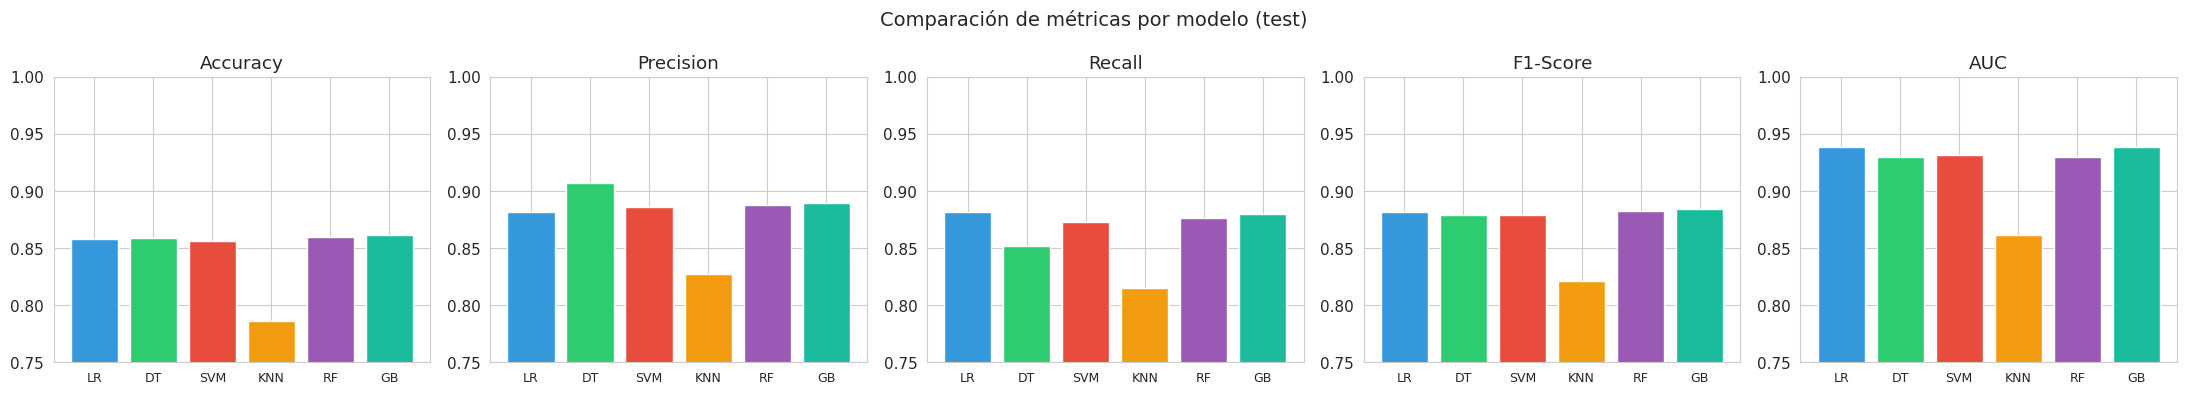

In [36]:
# E3.24  Gráfico de barras comparativo
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC']
colors_models_s = ['#3498db', '#2ecc71', '#e74c3c', '#f39c12', '#9b59b6', '#1abc9c']
abrev = ['LR', 'DT', 'SVM', 'KNN', 'RF', 'GB']
for i, metric in enumerate(metric_names):
    vals = metrics_df_s[metric].values.astype(float)
    axes[i].bar(range(len(vals)), vals, color=colors_models_s)
    axes[i].set_title(metric)
    axes[i].set_ylim(0.75, 1.0)
    axes[i].set_xticks(range(len(vals)))
    axes[i].set_xticklabels(abrev, fontsize=9)
plt.suptitle('Comparación de métricas por modelo (test)', fontsize=14)
plt.tight_layout()
plt.show()

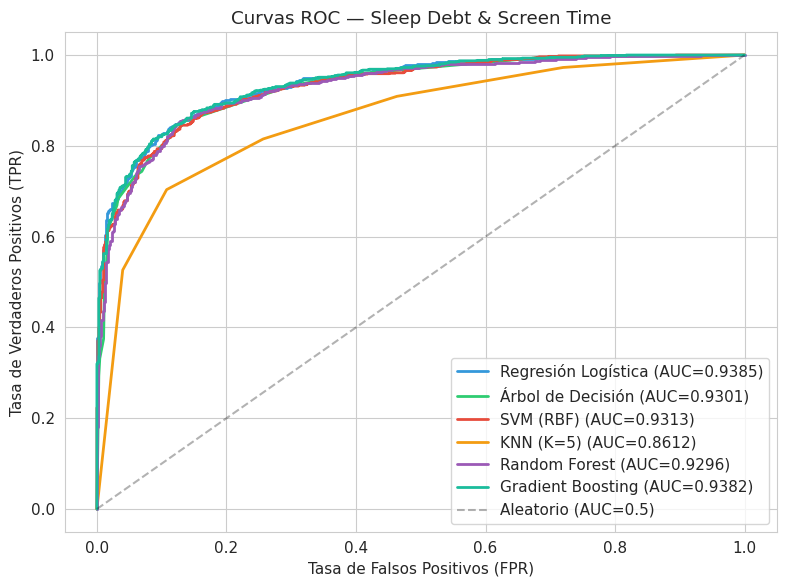

In [37]:
# E3.25  Curvas ROC superpuestas
fig, ax = plt.subplots(figsize=(8, 6))
for (name, model), color in zip(all_models_s.items(), colors_models_s):
    y_prob = model.predict_proba(Xs_test)[:, 1]
    fpr, tpr, _ = roc_curve(ys_test, y_prob)
    ax.plot(fpr, tpr, linewidth=2, color=color, label=f'{name} (AUC={auc(fpr, tpr):.4f})')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Aleatorio (AUC=0.5)')
ax.set_xlabel('Tasa de Falsos Positivos (FPR)')
ax.set_ylabel('Tasa de Verdaderos Positivos (TPR)')
ax.set_title('Curvas ROC — Sleep Debt & Screen Time')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [38]:
# E3.26  Matriz de selección
# Precisión y velocidad se calculan con los resultados reales (escala de 1 a 5 estrellas);
# interpretabilidad, escalabilidad y robustez son valoraciones cualitativas de cada algoritmo.
def estrellas(serie, mayor_es_mejor=True):
    s = serie if mayor_es_mejor else -serie
    rango = s.max() - s.min()
    n = ((s - s.min()) / rango * 4).round().astype(int) + 1 if rango > 0 else pd.Series(3, index=s.index)
    return n.map(lambda k: '★' * k + '☆' * (5 - k))

t_series_s = pd.Series(tiempos_s)
selection_matrix_s = pd.DataFrame({
    'Precisión predictiva (CV F1+AUC)': estrellas(cv_df_s['_f1'] + cv_df_s['_auc']),
    'Velocidad (train+pred)': estrellas(np.log10(t_series_s), mayor_es_mejor=False),
    'Interpretabilidad': pd.Series({'Regresión Logística': '★★★★☆', 'Árbol de Decisión': '★★★★★',
                                    'SVM (RBF)': '★★☆☆☆', 'KNN (K=5)': '★★★☆☆',
                                    'Random Forest': '★★☆☆☆', 'Gradient Boosting': '★★☆☆☆'}),
    'Escalabilidad': pd.Series({'Regresión Logística': '★★★★★', 'Árbol de Decisión': '★★★★☆',
                                'SVM (RBF)': '★★☆☆☆', 'KNN (K=5)': '★★☆☆☆',
                                'Random Forest': '★★★★☆', 'Gradient Boosting': '★★★☆☆'}),
    'Robustez a outliers': pd.Series({'Regresión Logística': '★★★☆☆', 'Árbol de Decisión': '★★★★☆',
                                      'SVM (RBF)': '★★★★☆', 'KNN (K=5)': '★★☆☆☆',
                                      'Random Forest': '★★★★★', 'Gradient Boosting': '★★★★☆'}),
})
print('=== Matriz de Selección de Modelos (Sleep Debt & Screen Time) ===')
display(selection_matrix_s)
print('\nTiempo medio train+pred por fold (s):')
print(t_series_s.round(4).to_string())

=== Matriz de Selección de Modelos (Sleep Debt & Screen Time) ===


,Precisión predictiva (CV F1+AUC),Velocidad (train+pred),Interpretabilidad,Escalabilidad,Robustez a outliers
Regresión Logística,★★★★★,★★★★★,★★★★☆,★★★★★,★★★☆☆
Árbol de Decisión,★★★★☆,★★★★★,★★★★★,★★★★☆,★★★★☆
SVM (RBF),★★★★★,★☆☆☆☆,★★☆☆☆,★★☆☆☆,★★★★☆
KNN (K=5),★☆☆☆☆,★★★★☆,★★★☆☆,★★☆☆☆,★★☆☆☆
Random Forest,★★★★★,★★☆☆☆,★★☆☆☆,★★★★☆,★★★★★
Gradient Boosting,★★★★★,★★☆☆☆,★★☆☆☆,★★★☆☆,★★★★☆



Tiempo medio train+pred por fold (s):
Regresión Logística    0.0695
Árbol de Decisión      0.0547
SVM (RBF)              5.1193
KNN (K=5)              0.1384
Random Forest          2.0939
Gradient Boosting      1.0680


In [39]:
# E3.27  Mejor modelo
mejor_cv_s = cv_df_s['_f1'].idxmax()
print(f'Mejor modelo por F1 en validación cruzada: {mejor_cv_s} (F1 = {cv_df_s.loc[mejor_cv_s, "_f1"]:.4f})')
print(f'Mejor modelo por AUC en validación cruzada: {cv_df_s["_auc"].idxmax()} (AUC = {cv_df_s["_auc"].max():.4f})')
print(f'Mejor modelo por F1 en test:     {metrics_df_s["F1-Score"].idxmax()} (F1 = {metrics_df_s["F1-Score"].max():.4f})')
print(f'Mejor modelo por Recall en test: {metrics_df_s["Recall"].idxmax()} (Recall = {metrics_df_s["Recall"].max():.4f})')

Mejor modelo por F1 en validación cruzada: Regresión Logística (F1 = 0.8906)
Mejor modelo por AUC en validación cruzada: Regresión Logística (AUC = 0.9421)
Mejor modelo por F1 en test:     Gradient Boosting (F1 = 0.8844)
Mejor modelo por Recall en test: Regresión Logística (Recall = 0.8816)


### Resumen comparativo

| Modelo | CV F1 | CV AUC | Test Recall | FN en test | Observación |
|---|---|---|---|---|---|
| **Regresión Logística** | **0.891** | **0.942** | **0.882** | **121** | Mejor en CV, el más rápido e interpretable |
| Árbol de Decisión | 0.880 | 0.933 | 0.852 | 151 | Mayor precisión (0.907), pero deja pasar más casos |
| SVM (RBF) | 0.883 | 0.934 | 0.873 | 130 | El kernel lineal (0.870 acc.) supera al RBF |
| KNN (K=5) | 0.832 | 0.868 | 0.815 | 189 | El más débil; mejora con K ≈ 81 (F1 0.85), sin alcanzar al resto |
| Random Forest | 0.886 | 0.935 | 0.877 | 126 | Robusto, pero no supera al modelo lineal |
| Gradient Boosting | 0.889 | 0.940 | 0.880 | 123 | Prácticamente empatado con la Regresión Logística |

### Justificación del mejor modelo (Ejercicio 3)

**Modelo recomendado: Regresión Logística.**

- Es el **mejor en validación cruzada** en F1 (0.891 ± 0.004) y en AUC (0.942 ± 0.006), y en test tiene el **mejor Recall de la clase "Deuda de sueño"** (0.882, 121 casos no detectados de 1 022), que es la métrica prioritaria.
- **Gradient Boosting** queda prácticamente empatado (CV F1 0.889, AUC 0.940; en test su F1 es 0.884 frente a 0.882, una diferencia de pocos casos entre 1 700). Con el mismo desempeño, se prefiere el modelo más simple, rápido (≈ 0.02 s frente a ≈ 0.65 s por fold) e interpretable.
- Que el modelo lineal gane (y que en SVM el kernel **lineal** supere al RBF y al polinomial) indica que la relación entre las variables y la deuda de sueño es **casi lineal**: los modelos no lineales no encuentran patrones adicionales.
- **Árbol de Decisión:** sin restricciones sobreajusta (train 1.00 frente a validación 0.80); con poda llega a 0.862 de accuracy. Es la alternativa si se necesitan reglas explícitas, pero es el que más casos con deuda deja pasar entre los modelos buenos (151 FN).
- **KNN** es el más débil: con 23 columnas (muchas dummies) las distancias pierden significado. Su mejor K (≈ 81) coincide con la regla empírica K ≈ √n.